# API for NOMAD

In [1]:
import requests
import getpass
import json
import pandas as pd
from typing import Dict, List, Tuple
from collections import Counter
import os

### access NOMAD

In [5]:
# --- Function to get an access token from the NOMAD API ---
def get_access_token(
    username: str, password: str, url: str, timeout_in_sec: int = 10
) -> str:
    """Authenticates with the NOMAD API and returns an access token."""
    response = requests.post(
        f"{url}/auth/token",
        data={"username": username, "password": password},
        timeout=timeout_in_sec,
    )
    response.raise_for_status()  # This will raise an error if login fails
    return response.json()["access_token"]

# --- Configuration ---
USERNAME = "anatitzhak"
PASSWORD = "Gaushle05369"  # It's better to use getpass in a real notebook
URL = "http://nomad.nanolab.dtu.dk/nomad-oasis/api/v1"

# --- Connect and Prepare Headers for Future Use ---
try:
    access_token = get_access_token(USERNAME, PASSWORD, URL)
    headers = {"Authorization": f"Bearer {access_token}"}
    print("✅ Connection successful. Access token obtained.")
    print("The 'headers' variable is now ready for future API calls.")
except requests.exceptions.HTTPError as e:
    print(f"❌ Connection failed. Error: {e.response.status_code}")
    print(e.response.json())

✅ Connection successful. Access token obtained.
The 'headers' variable is now ready for future API calls.


### Querry to find your sputtering sample, and what characterization was done on them

In [ ]:
# Get sputtering characterization table - FINAL VERSION with position extraction
def get_sputtering_characterization_table_v5(url: str, headers: dict, author_name: str = "Eugène Bertin") -> pd.DataFrame:
    """
    Query NOMAD API to find all sputtering depositions by a specific author
    and identify which characterization methods (EDX, XRD, XPS) are available.
    Extracts substrate position from CHARACTERIZATION entry names.
    
    Returns a DataFrame with columns: Sample Name, Position, Entry ID, Upload ID, EDX, XRD, XPS
    """
    
    print(f"Fetching sputtering depositions for author: {author_name}")
    print("="*80)
    
    # Query to get all DTUSputtering entries
    all_sputtering = []
    page_after_value = None
    
    while True:
        query = {
            "owner": "visible",
            "query": {
                "and": [
                    {"entry_type:all": ["DTUSputtering"]},
                    {"authors.name": author_name}
                ]
            },
            "pagination": {
                "page_size": 1000,
                "order_by": "entry_id",
                "page_after_value": page_after_value
            },
            "required": {
                "include": ["entry_id", "entry_name", "upload_id", "authors"]
            }
        }
        
        try:
            response = requests.post(
                f"{url}/entries/query",
                headers=headers,
                json=query,
                timeout=90,
            )
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get("data", [])
            if not page_data:
                break
            
            all_sputtering.extend(page_data)
            
            print(f"Processed {len(page_data)} entries, found {len(all_sputtering)} total so far...")
            
            pagination = response_json.get("pagination", {})
            page_after_value = pagination.get("next_page_after_value")
            
            if not page_after_value:
                break
            
        except Exception as e:
            print(f"❌ Error during query: {e}")
            import traceback
            traceback.print_exc()
            break
    
    print(f"\n✅ Found {len(all_sputtering)} sputtering depositions by {author_name}")
    print("="*80)
    
    if not all_sputtering:
        print("\n⚠️ No sputtering depositions found. Returning empty table.")
        return pd.DataFrame(columns=["Sample Name", "Position", "Entry ID", "Upload ID", "EDX", "XRD", "XPS"])
    
    # Fetch ALL entries by this author INCLUDING characterization entry names
    print("\n📊 Fetching all characterization entries with details...")
    
    all_author_entries = []
    page_after_value = None
    
    while True:
        query = {
            "owner": "visible",
            "query": {
                "authors.name": author_name
            },
            "pagination": {
                "page_size": 1000,
                "order_by": "entry_id",
                "page_after_value": page_after_value
            },
            "required": {
                "include": ["entry_id", "entry_type", "entry_name", "upload_id"]
            }
        }
        
        try:
            response = requests.post(
                f"{url}/entries/query",
                headers=headers,
                json=query,
                timeout=90,
            )
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get("data", [])
            if not page_data:
                break
            
            all_author_entries.extend(page_data)
            
            pagination = response_json.get("pagination", {})
            page_after_value = pagination.get("next_page_after_value")
            
            if not page_after_value:
                break
            
        except Exception as e:
            print(f"❌ Error fetching author entries: {e}")
            break
    
    print(f"✅ Found {len(all_author_entries)} total entries by {author_name}")
    
    # Group characterization entries by upload_id, entry_type, AND position
    # Structure: upload_characterizations[upload_id][position] = {"EDX": bool, "XRD": bool, "XPS": bool}
    upload_characterizations = {}
    
    position_codes = ['FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R', 'b', 'c', 'g', 't']
    
    for entry in all_author_entries:
        upload_id = entry.get("upload_id")
        entry_type = entry.get("entry_type")
        entry_name = entry.get("entry_name", "")
        
        # Only process characterization entries
        if entry_type not in ["EDXMeasurement", "DTUXRDMeasurement", "XPSMeasurement"]:
            continue
        
        # Extract position from entry name (4th element when split by space)
        # Example: "anait 0016 Ba FL XRD" -> position is "FL"
        parts = entry_name.split(" ")
        position = "Unknown"
        
        # Look for position code in the parts
        for part in parts:
            if part in position_codes:
                position = part
                break
        
        # Initialize nested structure if needed
        if upload_id not in upload_characterizations:
            upload_characterizations[upload_id] = {}
        
        if position not in upload_characterizations[upload_id]:
            upload_characterizations[upload_id][position] = {
                "EDX": False,
                "XRD": False,
                "XPS": False
            }
        
        # Mark the characterization type
        if entry_type == "EDXMeasurement":
            upload_characterizations[upload_id][position]["EDX"] = True
        elif entry_type == "DTUXRDMeasurement":
            upload_characterizations[upload_id][position]["XRD"] = True
        elif entry_type == "XPSMeasurement":
            upload_characterizations[upload_id][position]["XPS"] = True
    
    print(f"✅ Found characterizations across {len(upload_characterizations)} uploads")
    
    # Now create rows: one per sputtering entry per position
    print("\n📊 Building table with position-specific characterizations...")
    results = []
    
    for i, sputtering_entry in enumerate(all_sputtering, 1):
        entry_id = sputtering_entry.get("entry_id", "Unknown")
        entry_name = sputtering_entry.get("entry_name", "Unknown")
        upload_id = sputtering_entry.get("upload_id")
        
        # Check if this upload has characterizations
        if upload_id in upload_characterizations:
            # Create a row for each position found in characterizations
            positions_dict = upload_characterizations[upload_id]
            
            for position, char_types in positions_dict.items():
                results.append({
                    "Sample Name": entry_name,
                    "Position": position,
                    "Entry ID": entry_id,
                    "Upload ID": upload_id,
                    "EDX": "Yes" if char_types["EDX"] else "No",
                    "XRD": "Yes" if char_types["XRD"] else "No",
                    "XPS": "Yes" if char_types["XPS"] else "No"
                })
        else:
            # No characterizations found for this upload
            results.append({
                "Sample Name": entry_name,
                "Position": "No characterization",
                "Entry ID": entry_id,
                "Upload ID": upload_id,
                "EDX": "No",
                "XRD": "No",
                "XPS": "No"
            })
        
        if i % 10 == 0:
            print(f"  Processed {i}/{len(all_sputtering)} sputtering entries...")
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Summary statistics
    print("\n" + "="*80)
    print("SUMMARY")
    print("="*80)
    print(f"Total sputtering depositions: {len(all_sputtering)}")
    print(f"Total rows (deposition × position): {len(df)}")
    if len(df) > 0:
        print(f"With EDX: {(df['EDX'] == 'Yes').sum()}")
        print(f"With XRD: {(df['XRD'] == 'Yes').sum()}")
        print(f"With XPS: {(df['XPS'] == 'Yes').sum()}")
        print(f"With any characterization: {((df['EDX'] == 'Yes') | (df['XRD'] == 'Yes') | (df['XPS'] == 'Yes')).sum()}")
        
        # Show position breakdown
        print(f"\nPositions found:")
        position_counts = df['Position'].value_counts()
        for position, count in position_counts.items():
            print(f"  • {position}: {count} rows")
    print("="*80)
    
    return df


# ============================================================================
# ⚠️⚠️⚠️ CHANGE AUTHOR NAME HERE ⚠️⚠️⚠️
# Available options: "Anat Itzhak", "Lena Mittmann", "Inês Diogo"
# ============================================================================
AUTHOR_NAME = "Eugène Bertin"  # ← ← ← CHANGE THIS LINE TO CHANGE AUTHOR

print("="*80)
print(f"🔍 QUERYING DATA FOR AUTHOR: {AUTHOR_NAME}")
print("="*80)
print()

try:
    characterization_df = get_sputtering_characterization_table_v5(URL, headers, AUTHOR_NAME)
    
    # Display the table
    if len(characterization_df) > 0:
        print("\n📊 CHARACTERIZATION TABLE (with positions):")
        print(characterization_df.to_string(index=False))
        
        # Save to CSV - filename based on author name
        safe_filename = AUTHOR_NAME.lower().replace(" ", "_").replace("ê", "e").replace("í", "i")
        output_file = f"{safe_filename}_sputtering_characterization_with_positions.csv"
        characterization_df.to_csv(output_file, index=False)
        
        print("\n" + "="*80)
        print(f"✅ Table saved to: {output_file}")
        print(f"✅ Data retrieved for author: {AUTHOR_NAME}")
        print(f"✅ Table saved to: {output_file}")
        print(f"📁 Full path: {os.path.abspath(output_file)}")
        print("="*80)
    else:
        print("\n⚠️ No data to display or save.")
    
except NameError:
    print("❌ Error: Make sure you have run the first cell to define 'URL' and 'headers'.")
except Exception as e:
    print(f"❌ An unexpected error occurred: {e}")
    import traceback
    traceback.print_exc()

🔍 QUERYING DATA FOR AUTHOR: Eugène Bertin

Fetching sputtering depositions for author: Eugène Bertin
Processed 35 entries, found 35 total so far...

✅ Found 35 sputtering depositions by Eugène Bertin

📊 Fetching all characterization entries with details...
✅ Found 924 total entries by Eugène Bertin
✅ Found characterizations across 39 uploads

📊 Building table with position-specific characterizations...
  Processed 10/35 sputtering entries...
  Processed 20/35 sputtering entries...
  Processed 30/35 sputtering entries...

SUMMARY
Total sputtering depositions: 35
Total rows (deposition × position): 106
With EDX: 93
With XRD: 58
With XPS: 0
With any characterization: 102

Positions found:
  • BR: 27 rows
  • FR: 24 rows
  • BL: 24 rows
  • FL: 22 rows
  • G: 5 rows
  • No characterization: 4 rows

📊 CHARACTERIZATION TABLE (with positions):
    Sample Name            Position                     Entry ID              Upload ID EDX XRD XPS
  eugbe 0023 Zr                  FR -VPHHMkyiDz0c-P

### same querry but for RTP

In [18]:
# Get RTP characterization table - with position extraction (works for any author)
def get_rtp_characterization_table(url: str, headers: dict, author_name: str = "Inês Diogo") -> pd.DataFrame:
    """
    Query NOMAD API to find all RTP entries by a specific author
    and identify which characterization methods (EDX, XRD, XPS, Raman) are available.
    Extracts substrate position from CHARACTERIZATION entry names.
    
    Returns a DataFrame with columns: Sample Name, Position, Entry ID, Upload ID, EDX, XRD, XPS, Raman
    """
    
    print(f"Fetching RTP entries for author: {author_name}")
    print("="*80)
    
    # Query to get all DtuRTP entries
    all_rtp = []
    page_after_value = None
    
    while True:
        query = {
            "owner": "visible",
            "query": {
                "and": [
                    {"entry_type:all": ["DtuRTP"]},
                    {"authors.name": author_name}
                ]
            },
            "pagination": {
                "page_size": 1000,
                "order_by": "entry_id",
                "page_after_value": page_after_value
            },
            "required": {
                "include": ["entry_id", "entry_name", "upload_id", "authors"]
            }
        }
        
        try:
            response = requests.post(
                f"{url}/entries/query",
                headers=headers,
                json=query,
                timeout=90,
            )
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get("data", [])
            if not page_data:
                break
            
            all_rtp.extend(page_data)
            
            print(f"Processed {len(page_data)} entries, found {len(all_rtp)} total so far...")
            
            pagination = response_json.get("pagination", {})
            page_after_value = pagination.get("next_page_after_value")
            
            if not page_after_value:
                break
            
        except Exception as e:
            print(f"❌ Error during query: {e}")
            import traceback
            traceback.print_exc()
            break
    
    print(f"\n✅ Found {len(all_rtp)} RTP entries by {author_name}")
    print("="*80)
    
    if not all_rtp:
        print("\n⚠️ No RTP entries found. Returning empty table.")
        return pd.DataFrame(columns=["Sample Name", "Position", "Entry ID", "Upload ID", "EDX", "XRD", "XPS", "Raman"])
    
    # Fetch ALL entries by this author INCLUDING characterization entry names
    print("\n📊 Fetching all characterization entries with details...")
    
    all_author_entries = []
    page_after_value = None
    
    while True:
        query = {
            "owner": "visible",
            "query": {
                "authors.name": author_name
            },
            "pagination": {
                "page_size": 1000,
                "order_by": "entry_id",
                "page_after_value": page_after_value
            },
            "required": {
                "include": ["entry_id", "entry_type", "entry_name", "upload_id"]
            }
        }
        
        try:
            response = requests.post(
                f"{url}/entries/query",
                headers=headers,
                json=query,
                timeout=90,
            )
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get("data", [])
            if not page_data:
                break
            
            all_author_entries.extend(page_data)
            
            pagination = response_json.get("pagination", {})
            page_after_value = pagination.get("next_page_after_value")
            
            if not page_after_value:
                break
            
        except Exception as e:
            print(f"❌ Error fetching author entries: {e}")
            break
    
    print(f"✅ Found {len(all_author_entries)} total entries by {author_name}")
    
    # Group characterization entries by upload_id, entry_type, AND position
    upload_characterizations = {}
    
    # Position codes for RTP entries
    position_codes = [
        'FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R', 'M',
        'fl', 'fr', 'bl', 'br', 'c', 'tl', 'tr', 'g', 't', 'b', 'l', 'r', 'm',
        'va', 'vb', 'vc', 'vd', 'VA', 'VB', 'VC', 'VD',
        'ha', 'hb', 'hc', 'hd', 'HA', 'HB', 'HC', 'HD',
        'bi', 'BI'
    ]
    
    for entry in all_author_entries:
        upload_id = entry.get("upload_id")
        entry_type = entry.get("entry_type")
        entry_name = entry.get("entry_name", "")
        
        # Only process characterization entries (including Raman for RTP)
        if entry_type not in ["EDXMeasurement", "DTUXRDMeasurement", "XPSMeasurement", "RamanMeasurement"]:
            continue
        
        # Extract position from entry name (4th element when split by space)
        # Example: "mittma 0025 Cu FR XRD 1" -> position is "FR"
        parts = entry_name.split(" ")
        position = "Unknown"
        
        # Look for position code in the parts
        for part in parts:
            if part in position_codes:
                position = part
                break
        
        # Initialize nested structure if needed
        if upload_id not in upload_characterizations:
            upload_characterizations[upload_id] = {}
        
        if position not in upload_characterizations[upload_id]:
            upload_characterizations[upload_id][position] = {
                "EDX": False,
                "XRD": False,
                "XPS": False,
                "Raman": False
            }
        
        # Mark the characterization type
        if entry_type == "EDXMeasurement":
            upload_characterizations[upload_id][position]["EDX"] = True
        elif entry_type == "DTUXRDMeasurement":
            upload_characterizations[upload_id][position]["XRD"] = True
        elif entry_type == "XPSMeasurement":
            upload_characterizations[upload_id][position]["XPS"] = True
        elif entry_type == "RamanMeasurement":
            upload_characterizations[upload_id][position]["Raman"] = True
    
    print(f"✅ Found characterizations across {len(upload_characterizations)} uploads")
    
    # Now create rows: one per RTP entry per position
    print("\n📊 Building table with position-specific characterizations...")
    results = []
    
    for i, rtp_entry in enumerate(all_rtp, 1):
        entry_id = rtp_entry.get("entry_id", "Unknown")
        entry_name = rtp_entry.get("entry_name", "Unknown")
        upload_id = rtp_entry.get("upload_id")
        
        # Check if this upload has characterizations
        if upload_id in upload_characterizations:
            # Create a row for each position found in characterizations
            positions_dict = upload_characterizations[upload_id]
            
            for position, char_types in positions_dict.items():
                results.append({
                    "Sample Name": entry_name,
                    "Position": position,
                    "Entry ID": entry_id,
                    "Upload ID": upload_id,
                    "EDX": "Yes" if char_types["EDX"] else "No",
                    "XRD": "Yes" if char_types["XRD"] else "No",
                    "XPS": "Yes" if char_types["XPS"] else "No",
                    "Raman": "Yes" if char_types["Raman"] else "No"
                })
        else:
            # No characterizations found for this upload
            results.append({
                "Sample Name": entry_name,
                "Position": "No characterization",
                "Entry ID": entry_id,
                "Upload ID": upload_id,
                "EDX": "No",
                "XRD": "No",
                "XPS": "No",
                "Raman": "No"
            })
        
        if i % 10 == 0:
            print(f"  Processed {i}/{len(all_rtp)} RTP entries...")
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Summary statistics
    print("\n" + "="*80)
    print("SUMMARY")
    print("="*80)
    print(f"Total RTP entries: {len(all_rtp)}")
    print(f"Total rows (RTP × position): {len(df)}")
    if len(df) > 0:
        print(f"With EDX: {(df['EDX'] == 'Yes').sum()}")
        print(f"With XRD: {(df['XRD'] == 'Yes').sum()}")
        print(f"With XPS: {(df['XPS'] == 'Yes').sum()}")
        print(f"With Raman: {(df['Raman'] == 'Yes').sum()}")
        print(f"With any characterization: {((df['EDX'] == 'Yes') | (df['XRD'] == 'Yes') | (df['XPS'] == 'Yes') | (df['Raman'] == 'Yes')).sum()}")
        
        # Show position breakdown
        print(f"\nPositions found:")
        position_counts = df['Position'].value_counts()
        for position, count in position_counts.items():
            print(f"  • {position}: {count} rows")
    print("="*80)
    
    return df


# ============================================================================
# ⚠️⚠️⚠️ CHANGE AUTHOR NAME HERE ⚠️⚠️⚠️
# Available options: "Anat Itzhak", "Lena Mittmann", "Inês Diogo"
# ============================================================================
RTP_AUTHOR_NAME = "Inês Diogo"  # ← ← ← CHANGE THIS LINE TO CHANGE AUTHOR

print("="*80)
print(f"🔍 QUERYING RTP DATA FOR AUTHOR: {RTP_AUTHOR_NAME}")
print("="*80)
print()

try:
    rtp_characterization_df = get_rtp_characterization_table(URL, headers, RTP_AUTHOR_NAME)
    
    # Display the table
    if len(rtp_characterization_df) > 0:
        print("\n📊 RTP CHARACTERIZATION TABLE (with positions):")
        print(rtp_characterization_df.to_string(index=False))
        
        # Save to CSV - filename based on author name
        safe_filename = RTP_AUTHOR_NAME.lower().replace(" ", "_").replace("ê", "e").replace("í", "i")
        output_file = f"{safe_filename}_rtp_characterization_with_positions.csv"
        rtp_characterization_df.to_csv(output_file, index=False)
        
        print("\n" + "="*80)
        print(f"✅ Table saved to: {output_file}")
        print(f"✅ Data retrieved for author: {RTP_AUTHOR_NAME}")
        print(f"✅ Table saved to: {output_file}")
        print(f"📁 Full path: {os.path.abspath(output_file)}")
        print("="*80)
    else:
        print("\n⚠️ No data to display or save.")
    
except NameError:
    print("❌ Error: Make sure you have run the first cell to define 'URL' and 'headers'.")
except Exception as e:
    print(f"❌ An unexpected error occurred: {e}")
    import traceback
    traceback.print_exc()

🔍 QUERYING RTP DATA FOR AUTHOR: Inês Diogo

Fetching RTP entries for author: Inês Diogo
Processed 12 entries, found 12 total so far...

✅ Found 12 RTP entries by Inês Diogo

📊 Fetching all characterization entries with details...
✅ Found 497 total entries by Inês Diogo
✅ Found characterizations across 33 uploads

📊 Building table with position-specific characterizations...
  Processed 10/12 RTP entries...

SUMMARY
Total RTP entries: 12
Total rows (RTP × position): 39
With EDX: 39
With XRD: 0
With XPS: 0
With Raman: 0
With any characterization: 39

Positions found:
  • hc: 12 rows
  • hb: 12 rows
  • ha: 8 rows
  • hd: 7 rows

📊 RTP CHARACTERIZATION TABLE (with positions):
     Sample Name Position                     Entry ID              Upload ID EDX XRD XPS Raman
indiogo 0011 RTP       hc 9cQNN0iU6VJYErDNbTneWEQPk4zc WFGM6qV1QUGD1nPiSusI0Q Yes  No  No    No
indiogo 0011 RTP       ha 9cQNN0iU6VJYErDNbTneWEQPk4zc WFGM6qV1QUGD1nPiSusI0Q Yes  No  No    No
indiogo 0011 RTP       hd 9cQNN

### query for entries

In [3]:
def query_nomad(query: dict, url: str, headers: dict, timeout_in_sec: int = 60) -> dict:
    """Sends a query to the NOMAD API and returns the JSON response."""
    response = requests.post(
        f"{url}/entries/query",  # Using the /query endpoint is best for getting counts
        headers=headers,
        json=query,
        timeout=timeout_in_sec,
    )
    response.raise_for_status()
    return response.json()

# --- Query 1: Get total number of entries ---
# An empty query matches everything. We only need the count, so page_size is 1.
total_query = {
    "owner": "visible",
    "query": {},
    "pagination": {
        "page_size": 1
    }
}

# --- Query 2: Get 'DTUSputtering' entries ---
sputtering_query = {
    "owner": "visible",
    "query": {
        "entry_type:all": ["DTUSputtering"]
    },
    "pagination": {
        "page_size": 1
    }
}

# --- Query 3: Get 'DtuRTP' entries ---
rtp_query = {
    "owner": "visible",
    "query": {
        "entry_type:all": ["DtuRTP"]
    },
    "pagination": {
        "page_size": 1
    }
}

# --- Execute queries and print results ---
try:
    # Execute the query for the total count
    total_response = query_nomad(total_query, URL, headers)
    total_count = total_response.get('pagination', {}).get('total', 0)
    print(f"Total entries found: {total_count}")

    # Execute the query for DTUSputtering
    sputtering_response = query_nomad(sputtering_query, URL, headers)
    sputtering_count = sputtering_response.get('pagination', {}).get('total', 0)
    print(f"  - 'DTUSputtering' entries: {sputtering_count}")

    # Execute the query for DtuRTP
    rtp_response = query_nomad(rtp_query, URL, headers)
    rtp_count = rtp_response.get('pagination', {}).get('total', 0)
    print(f"  - 'DtuRTP' entries: {rtp_count}")

except requests.exceptions.RequestException as e:
    print(f"❌ A query failed. An error occurred: {e}")
    if hasattr(e, 'response') and e.response is not None:
        print(f"Server Response: {e.response.json()}")
except NameError:
     print("❌ Error: Make sure you have run the first cell to define 'URL' and 'headers'.")

Total entries found: 3412
  - 'DTUSputtering' entries: 122
  - 'DtuRTP' entries: 32


### sorting Entry types

In [13]:


all_entries = []
page_after_value = None
total_entries = 0

print("Starting to fetch the 'entry_type' field from all entries...")

while True:
    # Query for a page of entries, asking ONLY for the top-level entry_type
    query = {
        "owner": "visible",
        "pagination": {
            "page_size": 1000,
            "order_by": "entry_id",
            "page_after_value": page_after_value
        },
        "required": {
            "include": ["entry_type"] # Ask for the direct, top-level field
        }
    }

    try:
        response = requests.post(
            f"{URL}/entries/query", # Using the faster /query endpoint is fine for this
            headers=headers,
            json=query,
            timeout=60,
        )
        response.raise_for_status()
        response_json = response.json()
        
        page_data = response_json.get('data', [])
        all_entries.extend(page_data)

        if not total_entries:
            total_entries = response_json.get('pagination', {}).get('total', 0)
            
        page_after_value = response_json.get('pagination', {}).get('next_page_after_value')
        
        print(f"  ... fetched {len(all_entries)} / {total_entries} entries")

        if not page_after_value or not page_data:
            break

    except Exception as e:
        print(f"❌ An error occurred during fetching: {e}")
        break

print("\nFetching complete.")
print("-" * 30)

# --- COUNTING STEP ---
if all_entries:
    # Now we can directly access 'entry_type'
    entry_types = [entry['entry_type'] for entry in all_entries if 'entry_type' in entry]
    
    type_counts = Counter(entry_types)
    
    print("Found the following entry types:\n")
    for entry_type, count in type_counts.items():
        print(f"- {entry_type}: {count} entries")
else:
    print("No entries were fetched.")

Starting to fetch the 'entry_type' field from all entries...
  ... fetched 1000 / 3414 entries
  ... fetched 2000 / 3414 entries
  ... fetched 3000 / 3414 entries
  ... fetched 3414 / 3414 entries

Fetching complete.
------------------------------
Found the following entry types:

- EDXMeasurement: 400 entries
- DTUCombinatorialLibrary: 820 entries
- DTUSubstrate: 936 entries
- DTUSputtering: 122 entries
- DTULibraryCleaving: 33 entries
- DTUXRDMeasurement: 225 entries
- DtuJupyterAnalysis: 85 entries
- DtuRTP: 32 entries
- DTUXpsMeasurement: 3 entries
- DtuJupyterAnalysisTemplate: 23 entries
- DTUSubstrateBatch: 12 entries
- VASP DFT SinglePoint: 13 entries
- DTUTarget: 21 entries
- Workflow: 7 entries
- DTUCombinatorialSample: 2 entries
- VASP GeometryOptimization: 1 entries
- DTUGasSupply: 1 entries
- ELNXRayDiffraction: 1 entries


### count entries

In [6]:


# --- Function to fetch all entry IDs (no changes needed) ---
def fetch_all_entry_ids(entry_type: str, url: str, headers: dict) -> list:
    all_ids = []
    page_after_value = None
    print(f"Fetching all entry IDs for '{entry_type}'...")
    
    while True:
        query = {
            "owner": "visible",
            "query": { "entry_type:all": [entry_type] },
            "pagination": { "page_size": 1000, "order_by": "entry_id", "page_after_value": page_after_value },
            "required": { "include": ["entry_id"] }
        }
        try:
            response = requests.post(
                f"{url}/entries/query", headers=headers, json=query, timeout=90)
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get('data', [])
            all_ids.extend([entry['entry_id'] for entry in page_data])
            
            page_after_value = response_json.get('pagination', {}).get('next_page_after_value')
            if not page_after_value or not page_data:
                break
        except Exception as e:
            print(f"❌ An error occurred while fetching IDs: {e}")
            return []
            
    return all_ids

# --- Function to fetch and count measurements that reference the libraries ---
def fetch_and_count_by_final_reference(entry_type: str, library_ids: list, url: str, headers: dict) -> int:
    all_measurements = []
    id_batches = [library_ids[i:i + 200] for i in range(0, len(library_ids), 200)]
    
    print(f"\nQuerying for '{entry_type}' entries referencing the libraries...")
    
    for i, id_batch in enumerate(id_batches):
        query = {
            "owner": "visible",
            "query": {
                "and": [
                    { "entry_type:all": [entry_type] },
                    { "entry_references.target_entry_id:any": id_batch }
                ]
            },
            "pagination": { "page_size": 1000 },
            "required": { "data": "*" }  # Get all archive data including results
        }
        
        try:
            response = requests.post(
                f"{url}/entries/archive/query", headers=headers, json=query, timeout=180)
            response.raise_for_status()
            all_measurements.extend(response.json().get('data', []))
            print(f"  ... batch {i+1}/{len(id_batches)} complete.")
        except Exception as e:
            print(f"❌ An error occurred in a batch query: {e}")
            return -1
    
    print(f"  ... found {len(all_measurements)} matching '{entry_type}' entries.")
    
    # Count total measurement points
    total_points = 0
    for entry in all_measurements:
        results = entry.get('archive', {}).get('data', {}).get('results', [])
        if results:
            total_points += len(results)
    
    print(f"  ... counted {total_points} total measurement points.")
    return total_points

# --- MAIN EXECUTION ---
try:
    # 1. Get all library IDs
    library_ids = fetch_all_entry_ids("DTUCombinatorialLibrary", URL, headers)
    if not library_ids:
        raise Exception("Could not fetch library IDs.")
    print(f"✅ Found {len(library_ids)} library entries.")

    # 2. Get counts for XRD and EDX by reverse lookup
    total_xrd_points = fetch_and_count_by_final_reference("DTUXRDMeasurement", library_ids, URL, headers)
    total_edx_points = fetch_and_count_by_final_reference("EDXMeasurement", library_ids, URL, headers)

    # 3. Print the final summary
    print("\n" + "=" * 30)
    print("      FINAL RESULTS SUMMARY")
    print("=" * 30)
    print(f"📊 Total DTUXRDMeasurement points: {total_xrd_points}")
    print(f"📈 Total EDXMeasurement points:    {total_edx_points}")
    print("=" * 30)

except NameError:
    print("❌ Error: Make sure you have run Cell 1 to define 'URL' and 'headers'.")
except Exception as e:
    print(f"❌ An unexpected error occurred: {e}")

Fetching all entry IDs for 'DTUCombinatorialLibrary'...
✅ Found 828 library entries.

Querying for 'DTUXRDMeasurement' entries referencing the libraries...
  ... batch 1/5 complete.
  ... batch 2/5 complete.
  ... batch 3/5 complete.
  ... batch 4/5 complete.
  ... batch 5/5 complete.
  ... found 242 matching 'DTUXRDMeasurement' entries.
  ... counted 3120 total measurement points.

Querying for 'EDXMeasurement' entries referencing the libraries...
  ... batch 1/5 complete.
  ... batch 2/5 complete.
  ... batch 3/5 complete.
  ... batch 4/5 complete.
  ... batch 5/5 complete.
  ... found 456 matching 'EDXMeasurement' entries.
  ... counted 11276 total measurement points.

      FINAL RESULTS SUMMARY
📊 Total DTUXRDMeasurement points: 3120
📈 Total EDXMeasurement points:    11276


### Run this cell if you want a list of which samples are missing EDX, XRD, XPS

In [15]:
# Find sputtering samples without EDX and XRD - COMPLETE ANALYSIS
print("🔍 Complete characterization analysis for sputtering samples")
print("="*80)

if 'characterization_df' in dir() and len(characterization_df) > 0:
    # Filter for samples that don't have BOTH EDX and XRD
    missing_both = characterization_df[
        (characterization_df['EDX'] == 'No') & 
        (characterization_df['XRD'] == 'No')
    ]
    
    # Filter for samples missing EDX only (have XRD but no EDX)
    missing_edx = characterization_df[
        (characterization_df['EDX'] == 'No') & 
        (characterization_df['XRD'] == 'Yes')
    ]
    
    # Filter for samples missing XRD only (have EDX but no XRD)
    missing_xrd = characterization_df[
        (characterization_df['EDX'] == 'Yes') & 
        (characterization_df['XRD'] == 'No')
    ]
    
    # Filter for samples with ONLY EDX (no XRD, no XPS)
    only_edx = characterization_df[
        (characterization_df['EDX'] == 'Yes') & 
        (characterization_df['XRD'] == 'No') & 
        (characterization_df['XPS'] == 'No')
    ]
    
    # Filter for samples with ONLY XRD (no EDX, no XPS)
    only_xrd = characterization_df[
        (characterization_df['EDX'] == 'No') & 
        (characterization_df['XRD'] == 'Yes') & 
        (characterization_df['XPS'] == 'No')
    ]
    
    # Filter for samples with BOTH EDX and XRD (regardless of XPS)
    both_edx_xrd = characterization_df[
        (characterization_df['EDX'] == 'Yes') & 
        (characterization_df['XRD'] == 'Yes')
    ]
    
    # Filter for samples with NO characterization at all
    no_characterization = characterization_df[
        (characterization_df['EDX'] == 'No') & 
        (characterization_df['XRD'] == 'No') & 
        (characterization_df['XPS'] == 'No')
    ]
    
    print("\n📊 SAMPLES WITH BOTH EDX AND XRD:")
    print("="*80)
    if len(both_edx_xrd) > 0:
        print(f"✅ Found {len(both_edx_xrd)} samples with both EDX and XRD:\n")
        for idx, row in both_edx_xrd.iterrows():
            xps_status = "with XPS" if row['XPS'] == 'Yes' else "no XPS"
            print(f"• {row['Sample Name']} - Position: {row['Position']} ({xps_status})")
    else:
        print("❌ No samples have both EDX and XRD")
    
    print("\n📊 SAMPLES WITH ONLY EDX (no XRD, no XPS):")
    print("="*80)
    if len(only_edx) > 0:
        print(f"Found {len(only_edx)} samples with only EDX:\n")
        for idx, row in only_edx.iterrows():
            print(f"• {row['Sample Name']} - Position: {row['Position']}")
    else:
        print("✅ No samples have only EDX")
    
    print("\n📊 SAMPLES WITH ONLY XRD (no EDX, no XPS):")
    print("="*80)
    if len(only_xrd) > 0:
        print(f"Found {len(only_xrd)} samples with only XRD:\n")
        for idx, row in only_xrd.iterrows():
            print(f"• {row['Sample Name']} - Position: {row['Position']}")
    else:
        print("✅ No samples have only XRD")
    
    print("\n📊 SAMPLES MISSING BOTH EDX AND XRD:")
    print("="*80)
    if len(missing_both) > 0:
        print(f"Found {len(missing_both)} samples without both EDX and XRD:\n")
        for idx, row in missing_both.iterrows():
            xps_status = f"(has XPS)" if row['XPS'] == 'Yes' else "(no characterization)"
            print(f"• {row['Sample Name']} - Position: {row['Position']} {xps_status}")
    else:
        print("✅ All samples have either EDX or XRD (or both)!")
    
    print("\n📊 SAMPLES MISSING EDX (but have XRD):")
    print("="*80)
    if len(missing_edx) > 0:
        print(f"Found {len(missing_edx)} samples without EDX:\n")
        for idx, row in missing_edx.iterrows():
            xps_status = "with XPS" if row['XPS'] == 'Yes' else "no XPS"
            print(f"• {row['Sample Name']} - Position: {row['Position']} ({xps_status})")
    else:
        print("✅ No samples missing only EDX")
    
    print("\n📊 SAMPLES MISSING XRD (but have EDX):")
    print("="*80)
    if len(missing_xrd) > 0:
        print(f"Found {len(missing_xrd)} samples without XRD:\n")
        for idx, row in missing_xrd.iterrows():
            xps_status = "with XPS" if row['XPS'] == 'Yes' else "no XPS"
            print(f"• {row['Sample Name']} - Position: {row['Position']} ({xps_status})")
    else:
        print("✅ No samples missing only XRD")
    
    print("\n📊 SAMPLES WITH NO CHARACTERIZATION AT ALL:")
    print("="*80)
    if len(no_characterization) > 0:
        print(f"Found {len(no_characterization)} samples with no characterization:\n")
        for idx, row in no_characterization.iterrows():
            print(f"• {row['Sample Name']} - Position: {row['Position']}")
    else:
        print("✅ All samples have at least one characterization!")
    
    # Summary statistics
    print("\n" + "="*80)
    print("SUMMARY STATISTICS:")
    print("="*80)
    total = len(characterization_df)
    
    print(f"Total samples (with positions): {total}")
    print(f"\nCharacterization coverage:")
    print(f"  ✅ BOTH EDX and XRD: {len(both_edx_xrd)} ({100*len(both_edx_xrd)/total:.1f}%)")
    print(f"  📊 ONLY EDX (no XRD, no XPS): {len(only_edx)} ({100*len(only_edx)/total:.1f}%)")
    print(f"  📊 ONLY XRD (no EDX, no XPS): {len(only_xrd)} ({100*len(only_xrd)/total:.1f}%)")
    print(f"  ⚠️  Missing BOTH EDX and XRD: {len(missing_both)} ({100*len(missing_both)/total:.1f}%)")
    print(f"  ⚠️  Missing only EDX: {len(missing_edx)} ({100*len(missing_edx)/total:.1f}%)")
    print(f"  ⚠️  Missing only XRD: {len(missing_xrd)} ({100*len(missing_xrd)/total:.1f}%)")
    print(f"  ❌ NO characterization: {len(no_characterization)} ({100*len(no_characterization)/total:.1f}%)")
    print("="*80)
    
    # Save to CSV files
    if len(missing_both) > 0:
        missing_both.to_csv("samples_missing_edx_and_xrd.csv", index=False)
        print(f"\n💾 Samples missing both EDX and XRD saved to: samples_missing_edx_and_xrd.csv")
    
    if len(only_edx) > 0:
        only_edx.to_csv("samples_only_edx.csv", index=False)
        print(f"💾 Samples with only EDX saved to: samples_only_edx.csv")
    
    if len(only_xrd) > 0:
        only_xrd.to_csv("samples_only_xrd.csv", index=False)
        print(f"💾 Samples with only XRD saved to: samples_only_xrd.csv")
    
    if len(no_characterization) > 0:
        no_characterization.to_csv("samples_no_characterization.csv", index=False)
        print(f"💾 Samples with no characterization saved to: samples_no_characterization.csv")
    
else:
    print("❌ characterization_df not found. Please run the sputtering characterization table cell first.")

🔍 Complete characterization analysis for sputtering samples

📊 SAMPLES WITH BOTH EDX AND XRD:
✅ Found 29 samples with both EDX and XRD:

• anait 0028 Ba-Zr - Position: BL (no XPS)
• anait 0017 Ba - Position: FR (no XPS)
• anait 0017 Ba - Position: BL (no XPS)
• anait 0012 Ba-Zr - Position: BL (no XPS)
• anait 0012 Ba-Zr - Position: FL (no XPS)
• anait 0012 Ba-Zr - Position: FR (no XPS)
• anait 0011 Ba - Position: FL (no XPS)
• anait 0022 Ba - Position: BL (no XPS)
• anait 0022 Ba - Position: FR (no XPS)
• anait 0021 Ba - Position: BL (no XPS)
• anait 0021 Ba - Position: FR (no XPS)
• anait 0030 Ba-Zr - Position: BR (no XPS)
• anait 0030 Ba-Zr - Position: BL (no XPS)
• anait 0009 Ba Zr - Position: FL (no XPS)
• anait 0009 Ba Zr - Position: FR (no XPS)
• anait 0015 Ba - Position: BL (no XPS)
• anait 0015 Ba - Position: FR (no XPS)
• anait 0020 Ba - Position: BR (no XPS)
• anait 0020 Ba - Position: BL (no XPS)
• cbbmo 0001 Ba - Position: BL (no XPS)
• cbbmo 0001 Ba - Position: FL (no XPS)

### Fetching Authors

In [5]:
# Query to get all authors from entries
all_authors = []
author_entries = {}  # Dictionary to store entries per author
page_after_value = None
total_entries = 0

print("Fetching authors from all entries...")

while True:
    query = {
        "owner": "visible",
        "pagination": {
            "page_size": 1000,
            "order_by": "entry_id",
            "page_after_value": page_after_value
        },
        "required": {
            "include": ["authors", "entry_id"]  # Get authors and entry_id
        }
    }

    try:
        response = requests.post(
            f"{URL}/entries/query",
            headers=headers,
            json=query,
            timeout=60,
        )
        response.raise_for_status()
        response_json = response.json()
        
        page_data = response_json.get('data', [])
        
        # Process each entry
        for entry in page_data:
            authors = entry.get('authors', [])
            entry_id = entry.get('entry_id')
            
            # Add to our tracking
            for author in authors:
                author_name = author.get('name', 'Unknown')
                if author_name not in author_entries:
                    author_entries[author_name] = []
                author_entries[author_name].append(entry_id)

        if not total_entries:
            total_entries = response_json.get('pagination', {}).get('total', 0)
            
        page_after_value = response_json.get('pagination', {}).get('next_page_after_value')
        
        print(f"  ... processed {sum(len(v) for v in author_entries.values())} entries / {total_entries} total")

        if not page_after_value or not page_data:
            break

    except Exception as e:
        print(f"❌ An error occurred during fetching: {e}")
        break

print("\nFetching complete.")
print("=" * 60)

# Display results
if author_entries:
    print(f"\n📊 Found {len(author_entries)} unique authors:\n")
    
    # Sort by number of entries (descending)
    sorted_authors = sorted(author_entries.items(), key=lambda x: len(x[1]), reverse=True)
    
    for author_name, entries in sorted_authors:
        print(f"• {author_name}: {len(entries)} entries")
    
    print("\n" + "=" * 60)
    print(f"Total unique authors: {len(author_entries)}")
    print(f"Total entries processed: {sum(len(v) for v in author_entries.values())}")
else:
    print("No author information found.")

Fetching authors from all entries...
  ... processed 1486 entries / 3517 total
  ... processed 2968 entries / 3517 total
  ... processed 4411 entries / 3517 total
  ... processed 5159 entries / 3517 total

Fetching complete.

📊 Found 11 unique authors:

• Sarthak Kapoor: 1556 entries
• Lena Mittmann: 1465 entries
• Eugène Bertin: 924 entries
• Anat Itzhak: 582 entries
• Inês Diogo: 504 entries
• Pepe Marquez: 58 entries
• Alba Perez millan: 25 entries
• David Miles-skov: 14 entries
• Hampus Näsström: 14 entries
• Javier Sanz rodrigo: 14 entries
• Clara Moller: 3 entries

Total unique authors: 11
Total entries processed: 5159


In [8]:
# Fetch all entries by a specific author
target_author = "Anat Itzhak"
author_entries = []
page_after_value = None
total_found = 0

print(f"Fetching all entries by '{target_author}'...")

while True:
    query = {
        "owner": "visible",
        "query": {
            "authors.name": target_author  # Filter by author name
        },
        "pagination": {
            "page_size": 1000,
            "order_by": "entry_id",
            "page_after_value": page_after_value
        },
        "required": {
            "include": [
                "entry_id",
                "entry_type", 
                "upload_id",
                "mainfile",
                "upload_create_time",
                "entry_name"
            ]
        }
    }

    try:
        response = requests.post(
            f"{URL}/entries/query",
            headers=headers,
            json=query,
            timeout=90,
        )
        response.raise_for_status()
        response_json = response.json()
        
        page_data = response_json.get('data', [])
        author_entries.extend(page_data)
        
        if not total_found:
            total_found = response_json.get('pagination', {}).get('total', 0)
            
        page_after_value = response_json.get('pagination', {}).get('next_page_after_value')
        
        print(f"  ... fetched {len(author_entries)} / {total_found} entries")

        if not page_after_value or not page_data:
            break

    except Exception as e:
        print(f"❌ An error occurred during fetching: {e}")
        import traceback
        traceback.print_exc()
        break

print("\nFetching complete.")
print("=" * 60)

# Display results
if author_entries:
    print(f"\n✅ Found {len(author_entries)} entries by '{target_author}':\n")
    
    # Group by entry type
    by_type = {}
    for entry in author_entries:
        entry_type = entry.get('entry_type', 'Unknown')
        if entry_type not in by_type:
            by_type[entry_type] = []
        by_type[entry_type].append(entry)
    
    # Display summary
    print("📊 Entries by type:")
    for entry_type, entries in sorted(by_type.items()):
        print(f"  • {entry_type}: {len(entries)} entries")
    
    # Now fetch the files for each upload
    print("\n" + "=" * 60)
    print("📁 Fetching file lists for each upload...")
    
    unique_uploads = list(set(entry.get('upload_id') for entry in author_entries if entry.get('upload_id')))
    print(f"Found {len(unique_uploads)} unique uploads\n")
    
    upload_files = {}
    for i, upload_id in enumerate(unique_uploads):
        try:
            # Get files for this upload
            files_response = requests.get(
                f"{URL}/uploads/{upload_id}/raw",
                headers=headers,
                timeout=30
            )
            files_response.raise_for_status()
            files_data = files_response.json()
            
            # Store the file list
            upload_files[upload_id] = files_data
            
            # Show log files specifically
            log_files = [f for f in files_data if f.endswith('.log') or 'log' in f.lower()]
            if log_files:
                print(f"Upload {i+1}/{len(unique_uploads)} ({upload_id[:16]}...):")
                for log_file in log_files:
                    print(f"  📄 {log_file}")
            
        except Exception as e:
            print(f"  ❌ Error fetching files for upload {upload_id}: {e}")
    
    print("\n" + "=" * 60)
    print(f"✅ Total entries: {len(author_entries)}")
    print(f"✅ Total uploads: {len(unique_uploads)}")
    
    # Store for later use
    print("\nVariables created:")
    print("  • author_entries: List of all entries")
    print("  • upload_files: Dictionary of upload_id -> file lists")

else:
    print(f"❌ No entries found for author '{target_author}'")
    print("Make sure the name is spelled exactly as it appears in NOMAD")

Fetching all entries by 'Anat Itzhak'...
  ... fetched 554 / 554 entries

Fetching complete.

✅ Found 554 entries by 'Anat Itzhak':

📊 Entries by type:
  • DTUCombinatorialLibrary: 188 entries
  • DTUSputtering: 41 entries
  • DTUSubstrate: 12 entries
  • DTUSubstrateBatch: 1 entries
  • DTUXRDMeasurement: 43 entries
  • DTUXpsMeasurement: 2 entries
  • DtuJupyterAnalysis: 13 entries
  • EDXMeasurement: 57 entries
  • ELNXRayDiffraction: 1 entries
  • Unknown: 190 entries
  • Workflow: 6 entries

📁 Fetching file lists for each upload...
Found 50 unique uploads

  ❌ Error fetching files for upload S7JcbbKyRguRwkYwt2Pd6A: 400 Client Error: Bad Request for url: http://nomad.nanolab.dtu.dk/nomad-oasis/api/v1/uploads/S7JcbbKyRguRwkYwt2Pd6A/raw
  ❌ Error fetching files for upload w3cp6SU_RvClud4nttwPJw: 400 Client Error: Bad Request for url: http://nomad.nanolab.dtu.dk/nomad-oasis/api/v1/uploads/w3cp6SU_RvClud4nttwPJw/raw
  ❌ Error fetching files for upload xp5p5kxtT0ai_vrhDTwvgA: 400 Client

In [14]:
# Extract deposition time data from DTUSputtering entries
print("📊 DEPOSITION TIME ANALYSIS")
print("="*60)

if 'sputtering_entries' in dir() and sputtering_entries:
    # First, inspect what time-related fields are available
    print("\n🔍 Inspecting time-related fields in first entry...")
    print("="*60)
    
    first_entry = sputtering_entries[0]
    archive_data = first_entry.get('archive', {}).get('data', {})
    dep_params = archive_data.get('deposition_parameters', {})
    
    # Find all time-related keys
    time_keys = [key for key in dep_params.keys() if 'time' in key.lower()]
    
    if time_keys:
        print("\n📋 Time-related fields found in deposition_parameters:")
        for key in sorted(time_keys):
            value = dep_params.get(key)
            print(f"  • {key}: {value} (type: {type(value).__name__})")
    else:
        print("\n❌ No 'time' fields found in deposition_parameters")
        print("\nShowing fields with 'duration' or 'period':")
        duration_keys = [key for key in dep_params.keys() if any(word in key.lower() for word in ['duration', 'period', 'second', 'minute'])]
        if duration_keys:
            for key in sorted(duration_keys):
                value = dep_params.get(key)
                print(f"  • {key}: {value}")
        else:
            print("No duration-related fields found either.")
            print("\nAll available keys (first 30):")
            for key in sorted(dep_params.keys())[:30]:
                print(f"  • {key}")
    
    # Now extract time data for all entries
    print("\n" + "="*60)
    print("📊 DEPOSITION TIME DATA TABLE")
    print("="*60 + "\n")
    
    time_data = []
    for entry in sputtering_entries:
        archive_data = entry.get('archive', {}).get('data', {})
        dep_params = archive_data.get('deposition_parameters', {})
        
        lab_id = archive_data.get('lab_id', 'Unknown')
        entry_id = entry.get('entry_id', 'Unknown')
        
        # Extract all possible time-related fields
        time_values = {}
        for key in dep_params.keys():
            if any(word in key.lower() for word in ['time', 'duration', 'period']):
                time_values[key] = dep_params.get(key, 'Not specified')
        
        # Create entry with lab_id, all time fields, and entry_id
        entry_data = {'Lab ID': lab_id}
        entry_data.update(time_values)
        entry_data['Entry ID'] = entry_id
        
        time_data.append(entry_data)
    
    # Create DataFrame for nice display
    df = pd.DataFrame(time_data)
    
    print(f"Found {len(df)} entries\n")
    if not df.empty:
        print(df.to_string(index=False))
        
        # Show statistics for numeric time values
        print("\n" + "="*60)
        print("📈 TIME STATISTICS")
        print("="*60)
        
        # Analyze each time-related column
        time_columns = [col for col in df.columns if col not in ['Lab ID', 'Entry ID']]
        
        for col in time_columns:
            numeric_values = []
            for val in df[col]:
                if val != 'Not specified' and val is not None:
                    try:
                        # Handle if it's already numeric or needs conversion
                        if isinstance(val, (int, float)):
                            numeric_values.append(float(val))
                        elif isinstance(val, str) and val.replace('.', '').replace('-', '').replace('e', '').isdigit():
                            numeric_values.append(float(val))
                    except:
                        pass
            
            if numeric_values:
                print(f"\n{col}:")
                print(f"  Range: {min(numeric_values):.2f} - {max(numeric_values):.2f}")
                print(f"  Average: {sum(numeric_values)/len(numeric_values):.2f}")
                print(f"  Median: {sorted(numeric_values)[len(numeric_values)//2]:.2f}")
                print(f"  Count: {len(numeric_values)} entries with values")
            else:
                # Check what non-numeric values we have
                non_numeric = [v for v in df[col] if v != 'Not specified' and v is not None]
                if non_numeric and len(set(non_numeric)) <= 5:  # Show if only a few unique values
                    print(f"\n{col} (non-numeric values):")
                    value_counts = {}
                    for v in non_numeric:
                        value_counts[str(v)] = value_counts.get(str(v), 0) + 1
                    for value, count in value_counts.items():
                        print(f"  '{value}': {count} entries")
    else:
        print("No time data found!")
        
else:
    print("❌ sputtering_entries not found. Please run the cell that fetches DTUSputtering entries first.")
    print("\nTo fetch the data, run this query:")
    print("""
sputtering_query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:all": ["DTUSputtering"]},
            {"authors.name": "Anat Itzhak"}
        ]
    },
    "pagination": {"page_size": 1000},
    "required": {"data": "*"}
}
response = requests.post(f"{URL}/entries/archive/query", headers=headers, json=sputtering_query, timeout=120)
sputtering_entries = response.json().get('data', [])
""")

📊 DEPOSITION TIME ANALYSIS

🔍 Inspecting time-related fields in first entry...

📋 Time-related fields found in deposition_parameters:
  • deposition_time: 1251.17 (type: float)

📊 DEPOSITION TIME DATA TABLE

Found 41 entries

           Lab ID  deposition_time                     Entry ID
 anait_0034_Ba-Zr         1251.170 -4Ftgrht4R05NKaWCLX8npaFkLrM
 anait_0028_Ba-Zr         1211.531 -Y1Kjb8qt9170WHHW_-dBUVzp3oa
 anait_0036_Ba-Zr         1745.643 2bsCUvoMOBqujglcH61dtSzWOm8B
anait_0002_BaS-Zr         5674.404 5ZhXgMZuR_bBapqtwVnTipSw5FCK
    anait_0010_Ba          893.440 5nR4VNRPtSlUG6HloArfS67f8QwK
    anait_0005_Ba         3609.574 CcfFtrXCe_ynLBVtyujEaJNE5Rjj
 anait_0039_Ba-Zr         1564.811 Db4qakO2wUBNwNi6gaJib-2zevrb
    anait_0014_Ba         3569.014 Dw-pM5LMsv7SemTb89Nr7En-6grc
          Unknown              NaN EmPIdt-seuEHAWV9BRCkrUgd-lGg
 anait_0032_Ba-Zr         1520.673 IBeeK4bI2VwjsDoeMXZPxFz7gDH6
 anait_0037_Ba-Zr         1870.050 IhRkGlt6XeVpjcDBmVkVtEkUTfgL
 anait

### Tests and stuff

In [ ]:
# Helper function to find XRD entry IDs from NOMAD
def find_xrd_entry_ids(url: str, headers: dict, sample_name: str = None, author_name: str = None, limit: int = 20):
    """Find XRD measurement entry IDs you can use to fetch spectra."""
    
    print("🔍 Searching for XRD measurement entries...")
    print("="*80)
    
    # Build query
    query_filters = [{"entry_type:all": ["DTUXRDMeasurement"]}]
    
    if author_name:
        query_filters.append({"authors.name": author_name})
    
    query = {
        "owner": "visible",
        "query": {"and": query_filters} if len(query_filters) > 1 else query_filters[0],
        "pagination": {"page_size": 1000},
        "required": {"include": ["entry_id", "entry_name", "upload_id"]}
    }
    
    try:
        response = requests.post(
            f"{url}/entries/query",
            headers=headers,
            json=query,
            timeout=90
        )
        response.raise_for_status()
        results = response.json().get("data", [])
        
        if not results:
            print("❌ No XRD measurements found")
            return []
        
        # Filter and format results
        xrd_list = []
        for entry in results:
            entry_id = entry.get('entry_id')
            entry_name = entry.get('entry_name', 'Unknown')
            
            # Filter by sample name if provided
            if sample_name and sample_name.lower() not in entry_name.lower():
                continue
            
            # Extract position
            parts = entry_name.split()
            position = "Unknown"
            position_codes = ['FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R']
            for part in parts:
                if part in position_codes:
                    position = part
                    break
            
            xrd_list.append({
                'entry_id': entry_id,
                'entry_name': entry_name,
                'position': position
            })
        
        if len(xrd_list) == 0:
            print(f"❌ No XRD measurements found matching your filters")
            return []
        
        print(f"✅ Found {len(xrd_list)} XRD measurement(s)\n")
        
        # Display first N results
        display_list = xrd_list[:limit]
        for i, xrd in enumerate(display_list, 1):
            print(f"{i}. Sample: {xrd['entry_name']}")
            print(f"   Position: {xrd['position']}")
            print(f"   Entry ID: {xrd['entry_id']}\n")
        
        if len(xrd_list) > limit:
            print(f"... showing first {limit} of {len(xrd_list)} entries")
            print(f"    Use limit parameter to see more")
        
        print("="*80)
        print("💡 Copy an 'Entry ID' from above to use in Step 2!")
        print("="*80)
        
        return xrd_list
        
    except Exception as e:
        print(f"❌ Error: {e}")
        return []


# ============================================================================
# SEARCH FOR XRD ENTRY IDs - Choose one option:
# ============================================================================

# Option 1: Find XRD entries by author
xrd_list = find_xrd_entry_ids(URL, headers, author_name="Anat Itzhak", limit=20)

# Option 2: Search for specific sample (uncomment to use)
# xrd_list = find_xrd_entry_ids(URL, headers, sample_name="0016", author_name="Anat Itzhak")

🔍 Fetching XRD data for entry: your_entry_id_here
❌ Error fetching data: 404 Client Error: Not Found for url: http://nomad.nanolab.dtu.dk/nomad-oasis/api/v1/entries/your_entry_id_here/archive
   Status code: 404


In [12]:
# Helper function to find XRD entry IDs from NOMAD
def find_xrd_entry_ids(url: str, headers: dict, sample_name: str = None, author_name: str = None, limit: int = 20):
    """Find XRD measurement entry IDs you can use to fetch spectra."""
    
    print("🔍 Searching for XRD measurement entries...")
    print("="*80)
    
    # Build query
    query_filters = [{"entry_type:all": ["DTUXRDMeasurement"]}]
    
    if author_name:
        query_filters.append({"authors.name": author_name})
    
    query = {
        "owner": "visible",
        "query": {"and": query_filters} if len(query_filters) > 1 else query_filters[0],
        "pagination": {"page_size": 1000},
        "required": {"include": ["entry_id", "entry_name", "upload_id"]}
    }
    
    try:
        response = requests.post(
            f"{url}/entries/query",
            headers=headers,
            json=query,
            timeout=90
        )
        response.raise_for_status()
        results = response.json().get("data", [])
        
        if not results:
            print("❌ No XRD measurements found")
            return []
        
        # Filter and format results
        xrd_list = []
        for entry in results:
            entry_id = entry.get('entry_id')
            entry_name = entry.get('entry_name', 'Unknown')
            
            # Filter by sample name if provided
            if sample_name and sample_name.lower() not in entry_name.lower():
                continue
            
            # Extract position
            parts = entry_name.split()
            position = "Unknown"
            position_codes = ['FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R']
            for part in parts:
                if part in position_codes:
                    position = part
                    break
            
            xrd_list.append({
                'entry_id': entry_id,
                'entry_name': entry_name,
                'position': position
            })
        
        if len(xrd_list) == 0:
            print(f"❌ No XRD measurements found matching your filters")
            return []
        
        print(f"✅ Found {len(xrd_list)} XRD measurement(s)\n")
        
        # Display first N results
        display_list = xrd_list[:limit]
        for i, xrd in enumerate(display_list, 1):
            print(f"{i}. Sample: {xrd['entry_name']}")
            print(f"   Position: {xrd['position']}")
            print(f"   Entry ID: {xrd['entry_id']}\n")
        
        if len(xrd_list) > limit:
            print(f"... showing first {limit} of {len(xrd_list)} entries")
            print(f"    Use limit parameter to see more")
        
        print("="*80)
        print("💡 Copy an 'Entry ID' from above to use in Step 2!")
        print("="*80)
        
        return xrd_list
        
    except Exception as e:
        print(f"❌ Error: {e}")
        return []


# ============================================================================
# SEARCH FOR XRD ENTRY IDs - Choose one option:
# ============================================================================

# Option 1: Find XRD entries by author
xrd_list = find_xrd_entry_ids(URL, headers, author_name="Anat Itzhak", limit=20)

# Option 2: Search for specific sample (uncomment to use)
# xrd_list = find_xrd_entry_ids(URL, headers, sample_name="0016", author_name="Anat Itzhak")

🔍 Searching for XRD measurement entries...
✅ Found 50 XRD measurement(s)

1. Sample: anait 0016 Ba FL XRD
   Position: FL
   Entry ID: -V9PT1GO34TpAPRPt3E1xjomXVWm

2. Sample: anait 0010 RTP b XRD
   Position: Unknown
   Entry ID: -a31KYTblU4jw8uMJ08knmCrf_Qw

3. Sample: anait 0021 Ba BL XRD
   Position: BL
   Entry ID: 1FWV7IADrj0BzjMtqrVjPkCmBLNb

4. Sample: anait 0028 Ba-Zr FR 0007 RTP XRD
   Position: FR
   Entry ID: 34qdtocXrfoTLakVnS1f1806UQ9-

5. Sample: anait 0021 Ba FR XRD
   Position: FR
   Entry ID: 3QQCnKAgjit83K5zSpEVANIOXiuQ

6. Sample: anait 0012 Ba-Zr BL XRD
   Position: BL
   Entry ID: 4jELAHLjO1FVuKJDcP7Iv8hkaUhZ

7. Sample: anait 0018 Ba FR XRD
   Position: FR
   Entry ID: 57NnmtOIWc-AUPAq39Qoa3Aex1Yg

8. Sample: anait 0016 BA FR XRD
   Position: FR
   Entry ID: 5Xpfd6SmZde6YL9qgqpZZ0RPVTgf

9. Sample: anait 0016 BA BL XRD
   Position: BL
   Entry ID: 8RqmCZ3syp5j8xrJtO36GkTlblX2

10. Sample: anait 0030 Ba-Zr BR XRD
   Position: BR
   Entry ID: ARK-wgH1qRq7-EaYiXUgu3

In [13]:
# ============================================================================
# ⚠️⚠️⚠️ PASTE YOUR XRD ENTRY ID HERE ⚠️⚠️⚠️
# ============================================================================
ENTRY_ID = "3QQCnKAgjit83K5zSpEVANIOXiuQ"  # ← Paste actual Entry ID from Step 1
# ============================================================================

# Fetch and plot the XRD spectrum
xrd_data = get_xrd_spectrum(URL, headers, ENTRY_ID)

if xrd_data:
    print("\n📊 Plotting XRD spectrum...")
    plot_xrd_spectrum(xrd_data, save_plot=True)
    
    # Save data to CSV
    xrd_df = pd.DataFrame({
        '2-theta': xrd_data['two_theta'],
        'Intensity': xrd_data['intensity']
    })
    csv_filename = f"xrd_data_{ENTRY_ID}.csv"
    xrd_df.to_csv(csv_filename, index=False)
    print(f"💾 Data saved to: {csv_filename}")
    print(f"📁 Full path: {os.path.abspath(csv_filename)}")

🔍 Fetching XRD data for entry: 3QQCnKAgjit83K5zSpEVANIOXiuQ
❌ No measurement data found in this entry


In [11]:
# Helper function to find XRD entry IDs from NOMAD
def find_xrd_entry_ids(url: str, headers: dict, sample_name: str = None, author_name: str = None, limit: int = 20):
    """Find XRD measurement entry IDs you can use to fetch spectra."""
    
    print("🔍 Searching for XRD measurement entries...")
    print("="*80)
    
    # Build query
    query_filters = [{"entry_type:all": ["DTUXRDMeasurement"]}]
    
    if author_name:
        query_filters.append({"authors.name": author_name})
    
    query = {
        "owner": "visible",
        "query": {"and": query_filters} if len(query_filters) > 1 else query_filters[0],
        "pagination": {"page_size": 1000},
        "required": {"include": ["entry_id", "entry_name", "upload_id"]}
    }
    
    try:
        response = requests.post(
            f"{url}/entries/query",
            headers=headers,
            json=query,
            timeout=90
        )
        response.raise_for_status()
        results = response.json().get("data", [])
        
        if not results:
            print("❌ No XRD measurements found")
            return []
        
        # Filter and format results
        xrd_list = []
        for entry in results:
            entry_id = entry.get('entry_id')
            entry_name = entry.get('entry_name', 'Unknown')
            
            # Filter by sample name if provided
            if sample_name and sample_name.lower() not in entry_name.lower():
                continue
            
            # Extract position
            parts = entry_name.split()
            position = "Unknown"
            position_codes = ['FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R']
            for part in parts:
                if part in position_codes:
                    position = part
                    break
            
            xrd_list.append({
                'entry_id': entry_id,
                'entry_name': entry_name,
                'position': position
            })
        
        if len(xrd_list) == 0:
            print(f"❌ No XRD measurements found matching your filters")
            return []
        
        print(f"✅ Found {len(xrd_list)} XRD measurement(s)\n")
        
        # Display first N results
        display_list = xrd_list[:limit]
        for i, xrd in enumerate(display_list, 1):
            print(f"{i}. Sample: {xrd['entry_name']}")
            print(f"   Position: {xrd['position']}")
            print(f"   Entry ID: {xrd['entry_id']}\n")
        
        if len(xrd_list) > limit:
            print(f"... showing first {limit} of {len(xrd_list)} entries")
            print(f"    Use limit parameter to see more")
        
        print("="*80)
        print("💡 Copy an 'Entry ID' from above to use in Step 2!")
        print("="*80)
        
        return xrd_list
        
    except Exception as e:
        print(f"❌ Error: {e}")
        return []


# ============================================================================
# SEARCH FOR XRD ENTRY IDs - Choose one option:
# ============================================================================

# Option 1: Find XRD entries by author
xrd_list = find_xrd_entry_ids(URL, headers, author_name="Anat Itzhak", limit=20)

# Option 2: Search for specific sample (uncomment to use)
# xrd_list = find_xrd_entry_ids(URL, headers, sample_name="0016", author_name="Anat Itzhak")

🔍 Searching for XRD measurement entries...
✅ Found 50 XRD measurement(s)

1. Sample: anait 0016 Ba FL XRD
   Position: FL
   Entry ID: -V9PT1GO34TpAPRPt3E1xjomXVWm

2. Sample: anait 0010 RTP b XRD
   Position: Unknown
   Entry ID: -a31KYTblU4jw8uMJ08knmCrf_Qw

3. Sample: anait 0021 Ba BL XRD
   Position: BL
   Entry ID: 1FWV7IADrj0BzjMtqrVjPkCmBLNb

4. Sample: anait 0028 Ba-Zr FR 0007 RTP XRD
   Position: FR
   Entry ID: 34qdtocXrfoTLakVnS1f1806UQ9-

5. Sample: anait 0021 Ba FR XRD
   Position: FR
   Entry ID: 3QQCnKAgjit83K5zSpEVANIOXiuQ

6. Sample: anait 0012 Ba-Zr BL XRD
   Position: BL
   Entry ID: 4jELAHLjO1FVuKJDcP7Iv8hkaUhZ

7. Sample: anait 0018 Ba FR XRD
   Position: FR
   Entry ID: 57NnmtOIWc-AUPAq39Qoa3Aex1Yg

8. Sample: anait 0016 BA FR XRD
   Position: FR
   Entry ID: 5Xpfd6SmZde6YL9qgqpZZ0RPVTgf

9. Sample: anait 0016 BA BL XRD
   Position: BL
   Entry ID: 8RqmCZ3syp5j8xrJtO36GkTlblX2

10. Sample: anait 0030 Ba-Zr BR XRD
   Position: BR
   Entry ID: ARK-wgH1qRq7-EaYiXUgu3

In [6]:
# DIAGNOSTIC: Check Lena Mittmann's RTP characterization entry names for position codes
print("🔍 Inspecting Lena Mittmann's RTP characterization entry names for position patterns")
print("="*80)

# First, let's check if there are any DtuRTP entries by Lena Mittmann
rtp_query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:all": ["DtuRTP"]},
            {"authors.name": "Lena Mittmann"}
        ]
    },
    "pagination": {
        "page_size": 20
    },
    "required": {
        "include": ["entry_id", "entry_name", "upload_id"]
    }
}

try:
    response = requests.post(
        f"{URL}/entries/query",
        headers=headers,
        json=rtp_query,
        timeout=60,
    )
    response.raise_for_status()
    rtp_entries = response.json().get('data', [])
    
    print(f"\n✅ Found {len(rtp_entries)} DtuRTP entries by Len Mittmann\n")
    
    if len(rtp_entries) > 0:
        # Show first few RTP entries
        print("RTP Entries:")
        for i, entry in enumerate(rtp_entries[:10], 1):
            print(f"  {i}. {entry.get('entry_name')} (Upload: {entry.get('upload_id')[:16]}...)")
        
        # Now fetch characterization entries for Len Mittmann
        print("\n" + "="*80)
        print("Fetching characterization entries...")
        print("="*80 + "\n")
        
        char_query = {
            "owner": "visible",
            "query": {
                "and": [
                    {"entry_type:any": ["EDXMeasurement", "DTUXRDMeasurement", "XPSMeasurement", "RamanMeasurement"]},
                    {"authors.name": "Len Mittmann"}
                ]
            },
            "pagination": {
                "page_size": 50
            },
            "required": {
                "include": ["entry_id", "entry_name", "entry_type", "upload_id", "mainfile"]
            }
        }
        
        response = requests.post(
            f"{URL}/entries/query",
            headers=headers,
            json=char_query,
            timeout=60,
        )
        response.raise_for_status()
        char_data = response.json().get('data', [])
        
        # Filter for entries that might be related to RTP
        rtp_related = [e for e in char_data if 'RTP' in e.get('entry_name', '').upper() or 'rtp' in e.get('mainfile', '')]
        
        print(f"Found {len(rtp_related)} RTP-related characterization entries. Showing first 20:\n")
        
        position_codes = ['FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R', 
                         'fl', 'fr', 'bl', 'br', 'c', 'tl', 'tr', 'g', 't', 'b', 'l', 'r',
                         'a', 'A', 'd', 'D', 'e', 'E', 'f', 'F']
        
        for i, entry in enumerate(rtp_related[:20], 1):
            entry_name = entry.get('entry_name', 'Unknown')
            entry_type = entry.get('entry_type', 'Unknown')
            mainfile = entry.get('mainfile', 'N/A')
            
            print(f"{i}. Type: {entry_type}")
            print(f"   Entry Name: '{entry_name}'")
            print(f"   Mainfile: '{mainfile}'")
            
            # Check for position codes
            name_parts_space = entry_name.split(' ')
            found_positions = [part for part in name_parts_space if part in position_codes]
            
            if found_positions:
                print(f"   ✅ Found positions in name: {found_positions}")
            
            # Check mainfile
            if mainfile and mainfile != 'N/A':
                mainfile_parts = mainfile.split('_')
                mainfile_positions = [part for part in mainfile_parts if part in position_codes]
                if mainfile_positions:
                    print(f"   ✅ Mainfile has positions: {mainfile_positions}")
            
            print()
        
        print("="*80)
        print("📋 ANALYSIS:")
        print("Look at the position pattern in RTP characterization entries above.")
        print("Identify which element contains the position (a, b, c, d, etc. or FL, FR, BL, BR, etc.)")
        print("="*80)
    else:
        print("⚠️ No DtuRTP entries found for Len Mittmann.")
        print("Let's check what authors have RTP entries...")
        
        # Check all RTP entries
        all_rtp_query = {
            "owner": "visible",
            "query": {
                "entry_type:all": ["DtuRTP"]
            },
            "pagination": {
                "page_size": 100
            },
            "required": {
                "include": ["entry_id", "entry_name", "authors"]
            }
        }
        
        response = requests.post(
            f"{URL}/entries/query",
            headers=headers,
            json=all_rtp_query,
            timeout=60,
        )
        response.raise_for_status()
        all_rtp = response.json().get('data', [])
        
        # Get unique authors
        authors = set()
        for entry in all_rtp:
            for author in entry.get('authors', []):
                authors.add(author.get('name', 'Unknown'))
        
        print(f"\nFound {len(all_rtp)} total DtuRTP entries by these authors:")
        for author in sorted(authors):
            count = sum(1 for e in all_rtp if any(a.get('name') == author for a in e.get('authors', [])))
            print(f"  • {author}: {count} entries")
    
except Exception as e:
    print(f"❌ Error: {e}")
    import traceback
    traceback.print_exc()

🔍 Inspecting Lena Mittmann's RTP characterization entry names for position patterns

✅ Found 11 DtuRTP entries by Len Mittmann

RTP Entries:
  1. mittma 0007 RTP (Upload: 4TNWieqFSEKBlGEg...)
  2. mittma 0010 RTP (Upload: FuI6WjFpSoGLMirZ...)
  3. mittma 0005 RTP (Upload: ajTN0ZjcQZiEHSTv...)
  4. mittma 0003 RTP (Upload: YZLvOd7kSRab8_lt...)
  5. mittma 0008 RTP (Upload: wd3jbWtYTJ-zBNyr...)
  6. mittma 0002 RTP (Upload: wBR9JfYsRcmaq-9R...)
  7. mittma 0006 RTP (Upload: kl8X1MZ-QXuwxBca...)
  8. mittma 0011 RTP (Upload: VRbu6yjrR_SoBCok...)
  9. mittma 0004 RTP (Upload: cyMIjpPJQH-8LrIj...)
  10. mittma 0001 RTP (Upload: PuNtQxmTRSSIe7sP...)

Fetching characterization entries...

Found 0 RTP-related characterization entries. Showing first 20:

📋 ANALYSIS:
Look at the position pattern in RTP characterization entries above.
Identify which element contains the position (a, b, c, d, etc. or FL, FR, BL, BR, etc.)


In [11]:
# DIAGNOSTIC: Check ALL Lena Mittmann characterization entries with extended position codes
print("🔍 Inspecting ALL Lena Mittmann characterization entry names")
print("="*80)

# Fetch ALL characterization entries for Lena Mittmann
char_query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:any": ["EDXMeasurement", "DTUXRDMeasurement", "XPSMeasurement", "RamanMeasurement"]},
            {"authors.name": "Lena Mittmann"}
        ]
    },
    "pagination": {
        "page_size": 100
    },
    "required": {
        "include": ["entry_id", "entry_name", "entry_type", "upload_id", "mainfile"]
    }
}

try:
    response = requests.post(
        f"{URL}/entries/query",
        headers=headers,
        json=char_query,
        timeout=60,
    )
    response.raise_for_status()
    char_data = response.json().get('data', [])
    
    print(f"\n✅ Found {len(char_data)} total characterization entries by Lena Mittmann\n")
    
    if len(char_data) > 0:
        print("Showing first 40 characterization entries:\n")
        
        # Extended position codes including your suggestions
        position_codes = [
            'FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R', 'M',
            'fl', 'fr', 'bl', 'br', 'c', 'tl', 'tr', 'g', 't', 'b', 'l', 'r', 'm',
            'bi', 'BI', 'ha', 'HA', 'hb', 'HB', 'hc', 'HC', 'hd', 'HD',
            'va', 'VA', 'vb', 'VB', 'vc', 'VC', 'vd', 'VD',
            'a', 'A', 'd', 'D', 'e', 'E', 'f', 'F', 'h', 'H'
        ]
        
        for i, entry in enumerate(char_data[:40], 1):
            entry_name = entry.get('entry_name', 'Unknown')
            entry_type = entry.get('entry_type', 'Unknown')
            mainfile = entry.get('mainfile', 'N/A')
            
            print(f"{i}. {entry_type}")
            print(f"   Name: '{entry_name}'")
            
            # Split and check
            name_parts_space = entry_name.split(' ')
            name_parts_underscore = entry_name.split('_')
            
            # Check for position codes in space-separated parts
            found_positions_space = [part for part in name_parts_space if part in position_codes]
            if found_positions_space:
                print(f"   ✅ Position (space): {found_positions_space}")
            
            # Check for position codes in underscore-separated parts
            found_positions_underscore = [part for part in name_parts_underscore if part in position_codes]
            if found_positions_underscore:
                print(f"   ✅ Position (underscore): {found_positions_underscore}")
            
            # Check mainfile
            if mainfile and mainfile != 'N/A':
                print(f"   File: '{mainfile}'")
                mainfile_parts = mainfile.split('_')
                mainfile_positions = [part for part in mainfile_parts if part in position_codes]
                if mainfile_positions:
                    print(f"   ✅ Mainfile position: {mainfile_positions}")
            
            print()
        
        print("="*80)
        print("📋 SUMMARY:")
        print("Position codes found in entries:")
        
        # Analyze all entries to find which position codes are actually used
        all_positions = set()
        for entry in char_data:
            entry_name = entry.get('entry_name', '')
            mainfile = entry.get('mainfile', '')
            
            # Check entry name
            for part in entry_name.split(' '):
                if part in position_codes:
                    all_positions.add(part)
            
            # Check mainfile
            for part in mainfile.split('_'):
                if part in position_codes:
                    all_positions.add(part)
        
        print(f"Unique position codes found: {sorted(all_positions)}")
        print("="*80)
    else:
        print("⚠️ No characterization entries found for Lena Mittmann")
        print("\nLet's check if there are RTP entries by Lena Mittmann...")
        
        # Check for RTP entries
        rtp_query = {
            "owner": "visible",
            "query": {
                "and": [
                    {"entry_type:all": ["DtuRTP"]},
                    {"authors.name": "Lena Mittmann"}
                ]
            },
            "pagination": {
                "page_size": 20
            },
            "required": {
                "include": ["entry_id", "entry_name", "upload_id"]
            }
        }
        
        response = requests.post(
            f"{URL}/entries/query",
            headers=headers,
            json=rtp_query,
            timeout=60,
        )
        response.raise_for_status()
        rtp_data = response.json().get('data', [])
        
        print(f"\n✅ Found {len(rtp_data)} DtuRTP entries by Lena Mittmann")
        for i, entry in enumerate(rtp_data[:10], 1):
            print(f"  {i}. {entry.get('entry_name')}")
    
except Exception as e:
    print(f"❌ Error: {e}")
    import traceback
    traceback.print_exc()

🔍 Inspecting ALL Lena Mittmann characterization entry names

✅ Found 100 total characterization entries by Lena Mittmann

Showing first 40 characterization entries:

1. DTUXRDMeasurement
   Name: 'mittma 0025 Cu FR XRD 1'
   ✅ Position (space): ['FR']
   File: 'mittma_0025_Cu_FR_XRD_1.archive.json'
   ✅ Mainfile position: ['FR']

2. EDXMeasurement
   Name: 'mittma 0004 Cu BR EDX 1'
   ✅ Position (space): ['BR']
   File: 'mittma_0004_Cu_BR_EDX_1.archive.json'
   ✅ Mainfile position: ['BR']

3. DTUXRDMeasurement
   Name: 'mittma 0003 Cu BR XRD 1'
   ✅ Position (space): ['BR']
   File: 'mittma_0003_Cu_BR_XRD_1.archive.json'
   ✅ Mainfile position: ['BR']

4. EDXMeasurement
   Name: 'mittma 0034 Cu BL EDX 1'
   ✅ Position (space): ['BL']
   File: 'mittma_0034_Cu_BL_EDX_1.archive.json'
   ✅ Mainfile position: ['BL']

5. EDXMeasurement
   Name: 'mittma 0017 Cu FL EDX 1'
   ✅ Position (space): ['FL']
   File: 'mittma_0017_Cu_FL_EDX_1.archive.json'
   ✅ Mainfile position: ['FL']

6. EDXMeasure

In [19]:
# DIAGNOSTIC: Inspect entry name patterns to find position
print("🔍 Inspecting entry name patterns from characterization_df")
print("="*80)

if 'characterization_df' in dir() and len(characterization_df) > 0:
    print("\nFirst 10 entry names:")
    for i, name in enumerate(characterization_df['Sample Name'].head(10), 1):
        parts = name.split("_")
        print(f"\n{i}. '{name}'")
        print(f"   Split by '_': {parts}")
        print(f"   Number of parts: {len(parts)}")
        
        # Check if there's a space instead of underscore
        space_parts = name.split(" ")
        if len(space_parts) > 1:
            print(f"   Split by ' ': {space_parts}")
            print(f"   Number of space parts: {len(space_parts)}")
    
    print("\n" + "="*80)
    print("📋 ANALYSIS:")
    print("Look for patterns like FL, FR, BL, BR, C, TL, TR in the parts above")
    print("="*80)
else:
    print("❌ characterization_df not found. Run the main cell first.")

🔍 Inspecting entry name patterns from characterization_df

First 10 entry names:

1. 'anait 0034 Ba-Zr'
   Split by '_': ['anait 0034 Ba-Zr']
   Number of parts: 1
   Split by ' ': ['anait', '0034', 'Ba-Zr']
   Number of space parts: 3

2. 'anait 0028 Ba-Zr'
   Split by '_': ['anait 0028 Ba-Zr']
   Number of parts: 1
   Split by ' ': ['anait', '0028', 'Ba-Zr']
   Number of space parts: 3

3. 'anait 0036 Ba-Zr'
   Split by '_': ['anait 0036 Ba-Zr']
   Number of parts: 1
   Split by ' ': ['anait', '0036', 'Ba-Zr']
   Number of space parts: 3

4. 'anait 0002 BaS-Zr'
   Split by '_': ['anait 0002 BaS-Zr']
   Number of parts: 1
   Split by ' ': ['anait', '0002', 'BaS-Zr']
   Number of space parts: 3

5. 'anait 0010 Ba'
   Split by '_': ['anait 0010 Ba']
   Number of parts: 1
   Split by ' ': ['anait', '0010', 'Ba']
   Number of space parts: 3

6. 'anait 0005 Ba'
   Split by '_': ['anait 0005 Ba']
   Number of parts: 1
   Split by ' ': ['anait', '0005', 'Ba']
   Number of space parts: 3

7. 

In [20]:
# DIAGNOSTIC: Check characterization entry names for position codes
print("🔍 Inspecting characterization entry names for position patterns")
print("="*80)

# Fetch a few characterization entries to see their naming pattern
query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:any": ["EDXMeasurement", "DTUXRDMeasurement", "XPSMeasurement"]},
            {"authors.name": "Anat Itzhak"}
        ]
    },
    "pagination": {
        "page_size": 20
    },
    "required": {
        "include": ["entry_id", "entry_name", "entry_type", "upload_id", "mainfile"]
    }
}

try:
    response = requests.post(
        f"{URL}/entries/query",
        headers=headers,
        json=query,
        timeout=60,
    )
    response.raise_for_status()
    data = response.json().get('data', [])
    
    print(f"\nFound {len(data)} characterization entries. Showing first 15:\n")
    
    for i, entry in enumerate(data[:15], 1):
        entry_name = entry.get('entry_name', 'Unknown')
        entry_type = entry.get('entry_type', 'Unknown')
        mainfile = entry.get('mainfile', 'N/A')
        upload_id = entry.get('upload_id', 'N/A')
        
        print(f"{i}. Type: {entry_type}")
        print(f"   Entry Name: '{entry_name}'")
        print(f"   Mainfile: '{mainfile}'")
        
        # Check for position codes in entry_name
        name_parts_underscore = entry_name.split('_')
        name_parts_space = entry_name.split(' ')
        
        # Look for common position codes
        position_codes = ['FL', 'FR', 'BL', 'BR', 'C', 'TL', 'TR', 'G', 'T', 'B', 'L', 'R']
        found_positions = []
        
        for part in name_parts_underscore + name_parts_space:
            if part.upper() in position_codes:
                found_positions.append(part)
        
        if found_positions:
            print(f"   ✅ Found positions: {found_positions}")
        
        # Check mainfile for position codes
        if mainfile and mainfile != 'N/A':
            mainfile_parts = mainfile.split('_')
            mainfile_positions = []
            for part in mainfile_parts:
                if part.upper() in position_codes:
                    mainfile_positions.append(part)
            if mainfile_positions:
                print(f"   ✅ Mainfile has positions: {mainfile_positions}")
        
        print()
    
    print("="*80)
    print("📋 CONCLUSION:")
    print("Check if position codes (FL, FR, BL, BR, C, etc.) appear in:")
    print("  1. Characterization entry names")
    print("  2. Mainfile paths")
    print("="*80)
    
except Exception as e:
    print(f"❌ Error: {e}")
    import traceback
    traceback.print_exc()

🔍 Inspecting characterization entry names for position patterns

Found 20 characterization entries. Showing first 15:

1. Type: DTUXRDMeasurement
   Entry Name: 'anait 0016 Ba FL XRD'
   Mainfile: 'anait_0016_Ba_FL_XRD.archive.json'
   ✅ Found positions: ['FL']
   ✅ Mainfile has positions: ['FL']

2. Type: DTUXRDMeasurement
   Entry Name: 'anait 0010 RTP b XRD'
   Mainfile: 'anait_0010_RTP_b_XRD.archive.json'
   ✅ Found positions: ['b']
   ✅ Mainfile has positions: ['b']

3. Type: EDXMeasurement
   Entry Name: 'anait 0002 BaS-Zr BL EDX'
   Mainfile: 'anait_0002_BaS-Zr_BL_EDX.archive.json'
   ✅ Found positions: ['BL']
   ✅ Mainfile has positions: ['BL']

4. Type: DTUXRDMeasurement
   Entry Name: 'anait 0021 Ba BL XRD'
   Mainfile: 'anait_0021_Ba_BL_XRD.archive.json'
   ✅ Found positions: ['BL']
   ✅ Mainfile has positions: ['BL']

5. Type: EDXMeasurement
   Entry Name: 'anait 0023 Ba FL EDX'
   Mainfile: 'anait_0023_Ba_FL_EDX.archive.json'
   ✅ Found positions: ['FL']
   ✅ Mainfile has 

In [15]:
# DIAGNOSTIC: Investigate substrate references to understand the data structure
print("🔍 DIAGNOSTIC: Exploring substrate references in sputtering entries")
print("="*80)

try:
    # Get one sputtering entry with full archive data
    diagnostic_query = {
        "owner": "visible",
        "query": {
            "and": [
                {"entry_type:all": ["DTUSputtering"]},
                {"authors.name": "Anat Itzhak"}
            ]
        },
        "pagination": {
            "page_size": 1
        },
        "required": {
            "include": ["entry_id", "entry_name", "upload_id"],
            "data": "*"
        }
    }
    
    response = requests.post(
        f"{URL}/entries/archive/query",
        headers=headers,
        json=diagnostic_query,
        timeout=60,
    )
    response.raise_for_status()
    response_json = response.json()
    
    if response_json.get('data'):
        entry = response_json['data'][0]
        entry_name = entry.get('entry_name', 'Unknown')
        upload_id = entry.get('upload_id')
        archive_data = entry.get('archive', {}).get('data', {})
        
        print(f"✅ Inspecting entry: {entry_name}")
        print(f"   Upload ID: {upload_id}\n")
        print("="*80)
        
        # Check substrates field
        print("\n1️⃣ Checking archive.data.substrates:")
        print("-"*80)
        substrates = archive_data.get('substrates', [])
        if substrates:
            print(f"Found {len(substrates)} substrate(s)")
            for i, sub in enumerate(substrates):
                print(f"\nSubstrate {i+1}:")
                print(f"  name: {sub.get('name', 'N/A')}")
                print(f"  substrate (reference): {sub.get('substrate', 'N/A')}")
                print(f"  substrate_batch (reference): {sub.get('substrate_batch', 'N/A')}")
                print(f"  All keys: {list(sub.keys())}")
        else:
            print("No substrates found")
        
        # Try to extract substrate IDs from references
        print("\n2️⃣ Attempting to extract substrate entry IDs from references:")
        print("-"*80)
        substrate_entry_ids = []
        for sub in substrates:
            # The reference format is typically: "../uploads/{upload_id}/archive/{entry_id}#/data"
            substrate_ref = sub.get('substrate')
            if substrate_ref and isinstance(substrate_ref, str):
                # Extract entry ID from reference string
                parts = substrate_ref.split('/')
                if 'archive' in parts:
                    idx = parts.index('archive')
                    if idx + 1 < len(parts):
                        entry_id_part = parts[idx + 1].split('#')[0]  # Remove #/data if present
                        substrate_entry_ids.append(entry_id_part)
                        print(f"  Found substrate entry ID: {entry_id_part}")
        
        # Now fetch the actual substrate entries to see their data
        if substrate_entry_ids:
            print("\n3️⃣ Fetching actual substrate entry data:")
            print("-"*80)
            
            substrate_query = {
                "owner": "visible",
                "query": {
                    "entry_id:any": substrate_entry_ids
                },
                "pagination": {
                    "page_size": len(substrate_entry_ids)
                },
                "required": {
                    "include": ["entry_id", "entry_type", "entry_name"],
                    "data": "*"
                }
            }
            
            sub_response = requests.post(
                f"{URL}/entries/archive/query",
                headers=headers,
                json=substrate_query,
                timeout=60,
            )
            sub_response.raise_for_status()
            sub_data = sub_response.json().get('data', [])
            
            for sub_entry in sub_data:
                sub_id = sub_entry.get('entry_id')
                sub_name = sub_entry.get('entry_name', 'Unknown')
                sub_type = sub_entry.get('entry_type', 'Unknown')
                sub_archive = sub_entry.get('archive', {}).get('data', {})
                
                print(f"\nSubstrate Entry ID: {sub_id}")
                print(f"  Entry Type: {sub_type}")
                print(f"  Entry Name: {sub_name}")
                print(f"  Archive data keys: {list(sub_archive.keys())}")
                
                # Look for useful substrate info
                if 'lab_id' in sub_archive:
                    print(f"  lab_id: {sub_archive['lab_id']}")
                if 'name' in sub_archive:
                    print(f"  name: {sub_archive['name']}")
                if 'substrate_id' in sub_archive:
                    print(f"  substrate_id: {sub_archive['substrate_id']}")
                if 'material' in sub_archive:
                    print(f"  material: {sub_archive['material']}")
        
        print("\n" + "="*80)
        print("📋 CONCLUSION:")
        print("="*80)
        print("To get actual substrate names/materials, we need to:")
        print("1. Extract substrate entry IDs from the reference strings")
        print("2. Query those entries to get their actual data")
        print("3. Extract lab_id, name, or material from those entries")
        
    else:
        print("❌ No sputtering entries found")
        
except Exception as e:
    print(f"❌ Error during diagnostic: {e}")
    import traceback
    traceback.print_exc()

🔍 DIAGNOSTIC: Exploring substrate references in sputtering entries
✅ Inspecting entry: Unknown
   Upload ID: KlEtdT9LRWi5hf6VdsCvkg


1️⃣ Checking archive.data.substrates:
--------------------------------------------------------------------------------
Found 5 substrate(s)

Substrate 1:
  name: FL
  substrate (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/UTc6vL98PV3FGsi5QhMvRpEP-4zv#/data
  substrate_batch (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/CJX5ku47xZ0tFQUXP-5Gf2oKzpVC#/data
  All keys: ['name', 'substrate_batch', 'substrate', 'relative_position', 'position_x', 'position_y', 'rotation']

Substrate 2:
  name: FR
  substrate (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/4PQVnBKmdvZMkRKuzBFw3zvkPtTg#/data
  substrate_batch (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/CJX5ku47xZ0tFQUXP-5Gf2oKzpVC#/data
  All keys: ['name', 'substrate_batch', 'substrate', 'relative_position', 'position_x', 'position_y', 'rotation']

Substrate 3:
  name: BL
  s

In [16]:
# DIAGNOSTIC: Investigate substrate references to understand the data structure
print("🔍 DIAGNOSTIC: Exploring substrate references in sputtering entries")
print("="*80)

try:
    # Get one sputtering entry with full archive data
    diagnostic_query = {
        "owner": "visible",
        "query": {
            "and": [
                {"entry_type:all": ["DTUSputtering"]},
                {"authors.name": "Anat Itzhak"}
            ]
        },
        "pagination": {
            "page_size": 1
        },
        "required": {
            "include": ["entry_id", "entry_name", "upload_id"],
            "data": "*"
        }
    }
    
    response = requests.post(
        f"{URL}/entries/archive/query",
        headers=headers,
        json=diagnostic_query,
        timeout=60,
    )
    response.raise_for_status()
    response_json = response.json()
    
    if response_json.get('data'):
        entry = response_json['data'][0]
        entry_name = entry.get('entry_name', 'Unknown')
        upload_id = entry.get('upload_id')
        archive_data = entry.get('archive', {}).get('data', {})
        
        print(f"✅ Inspecting entry: {entry_name}")
        print(f"   Upload ID: {upload_id}\n")
        print("="*80)
        
        # Check substrates field
        print("\n1️⃣ Checking archive.data.substrates:")
        print("-"*80)
        substrates = archive_data.get('substrates', [])
        if substrates:
            print(f"Found {len(substrates)} substrate(s)")
            for i, sub in enumerate(substrates):
                print(f"\nSubstrate {i+1}:")
                print(f"  name: {sub.get('name', 'N/A')}")
                print(f"  substrate (reference): {sub.get('substrate', 'N/A')}")
                print(f"  substrate_batch (reference): {sub.get('substrate_batch', 'N/A')}")
                print(f"  All keys: {list(sub.keys())}")
        else:
            print("No substrates found")
        
        # Try to extract substrate IDs from references
        print("\n2️⃣ Attempting to extract substrate entry IDs from references:")
        print("-"*80)
        substrate_entry_ids = []
        for sub in substrates:
            # The reference format is typically: "../uploads/{upload_id}/archive/{entry_id}#/data"
            substrate_ref = sub.get('substrate')
            if substrate_ref and isinstance(substrate_ref, str):
                # Extract entry ID from reference string
                parts = substrate_ref.split('/')
                if 'archive' in parts:
                    idx = parts.index('archive')
                    if idx + 1 < len(parts):
                        entry_id_part = parts[idx + 1].split('#')[0]  # Remove #/data if present
                        substrate_entry_ids.append(entry_id_part)
                        print(f"  Found substrate entry ID: {entry_id_part}")
        
        # Now fetch the actual substrate entries to see their data
        if substrate_entry_ids:
            print("\n3️⃣ Fetching actual substrate entry data:")
            print("-"*80)
            
            substrate_query = {
                "owner": "visible",
                "query": {
                    "entry_id:any": substrate_entry_ids
                },
                "pagination": {
                    "page_size": len(substrate_entry_ids)
                },
                "required": {
                    "include": ["entry_id", "entry_type", "entry_name"],
                    "data": "*"
                }
            }
            
            sub_response = requests.post(
                f"{URL}/entries/archive/query",
                headers=headers,
                json=substrate_query,
                timeout=60,
            )
            sub_response.raise_for_status()
            sub_data = sub_response.json().get('data', [])
            
            for sub_entry in sub_data:
                sub_id = sub_entry.get('entry_id')
                sub_name = sub_entry.get('entry_name', 'Unknown')
                sub_type = sub_entry.get('entry_type', 'Unknown')
                sub_archive = sub_entry.get('archive', {}).get('data', {})
                
                print(f"\nSubstrate Entry ID: {sub_id}")
                print(f"  Entry Type: {sub_type}")
                print(f"  Entry Name: {sub_name}")
                print(f"  Archive data keys: {list(sub_archive.keys())}")
                
                # Look for useful substrate info
                if 'lab_id' in sub_archive:
                    print(f"  lab_id: {sub_archive['lab_id']}")
                if 'name' in sub_archive:
                    print(f"  name: {sub_archive['name']}")
                if 'substrate_id' in sub_archive:
                    print(f"  substrate_id: {sub_archive['substrate_id']}")
                if 'material' in sub_archive:
                    print(f"  material: {sub_archive['material']}")
        
        print("\n" + "="*80)
        print("📋 CONCLUSION:")
        print("="*80)
        print("To get actual substrate names/materials, we need to:")
        print("1. Extract substrate entry IDs from the reference strings")
        print("2. Query those entries to get their actual data")
        print("3. Extract lab_id, name, or material from those entries")
        
    else:
        print("❌ No sputtering entries found")
        
except Exception as e:
    print(f"❌ Error during diagnostic: {e}")
    import traceback
    traceback.print_exc()

🔍 DIAGNOSTIC: Exploring substrate references in sputtering entries
✅ Inspecting entry: Unknown
   Upload ID: KlEtdT9LRWi5hf6VdsCvkg


1️⃣ Checking archive.data.substrates:
--------------------------------------------------------------------------------
Found 5 substrate(s)

Substrate 1:
  name: FL
  substrate (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/UTc6vL98PV3FGsi5QhMvRpEP-4zv#/data
  substrate_batch (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/CJX5ku47xZ0tFQUXP-5Gf2oKzpVC#/data
  All keys: ['name', 'substrate_batch', 'substrate', 'relative_position', 'position_x', 'position_y', 'rotation']

Substrate 2:
  name: FR
  substrate (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/4PQVnBKmdvZMkRKuzBFw3zvkPtTg#/data
  substrate_batch (reference): ../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/CJX5ku47xZ0tFQUXP-5Gf2oKzpVC#/data
  All keys: ['name', 'substrate_batch', 'substrate', 'relative_position', 'position_x', 'position_y', 'rotation']

Substrate 3:
  name: BL
  s

In [17]:
# Get sputtering characterization table with actual substrate names (UPDATED VERSION)
def get_sputtering_characterization_table_v3(url: str, headers: dict, author_name: str = "Anat Itzhak") -> pd.DataFrame:
    """
    Query NOMAD API to find all sputtering depositions by a specific author
    and identify which characterization methods (EDX, XRD, XPS) are available.
    Now includes actual substrate material names instead of just position codes.
    
    Returns a DataFrame with columns: Sample Name, Substrate, Entry ID, Upload ID, EDX, XRD, XPS
    """
    
    print(f"Fetching sputtering depositions for author: {author_name}")
    print("="*80)
    
    # Query to get all DTUSputtering entries by this author with full archive data
    all_sputtering = []
    page_after_value = None
    
    while True:
        query = {
            "owner": "visible",
            "query": {
                "and": [
                    {"entry_type:all": ["DTUSputtering"]},
                    {"authors.name": author_name}
                ]
            },
            "pagination": {
                "page_size": 1000,
                "order_by": "entry_id",
                "page_after_value": page_after_value
            },
            "required": {
                "include": [
                    "entry_id",
                    "entry_name",
                    "upload_id",
                    "authors"
                ],
                "data": "*"  # Get archive data to access substrate info
            }
        }
        
        try:
            response = requests.post(
                f"{url}/entries/archive/query",
                headers=headers,
                json=query,
                timeout=90,
            )
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get("data", [])
            if not page_data:
                break
            
            all_sputtering.extend(page_data)
            
            print(f"Processed {len(page_data)} entries, found {len(all_sputtering)} total so far...")
            
            pagination = response_json.get("pagination", {})
            page_after_value = pagination.get("next_page_after_value")
            
            if not page_after_value:
                break
            
        except Exception as e:
            print(f"❌ Error during query: {e}")
            import traceback
            traceback.print_exc()
            break
    
    print(f"\n✅ Found {len(all_sputtering)} sputtering depositions by {author_name}")
    print("="*80)
    
    if not all_sputtering:
        print("\n⚠️ No sputtering depositions found. Returning empty table.")
        return pd.DataFrame(columns=["Sample Name", "Substrate", "Entry ID", "Upload ID", "EDX", "XRD", "XPS"])
    
    # STEP 1: Fetch ALL entries by this author for characterization matching
    print("\n📊 Fetching all characterization entries by author...")
    
    all_author_entries = []
    page_after_value = None
    
    while True:
        query = {
            "owner": "visible",
            "query": {
                "authors.name": author_name
            },
            "pagination": {
                "page_size": 1000,
                "order_by": "entry_id",
                "page_after_value": page_after_value
            },
            "required": {
                "include": [
                    "entry_id",
                    "entry_type",
                    "entry_name",
                    "upload_id"
                ]
            }
        }
        
        try:
            response = requests.post(
                f"{url}/entries/query",
                headers=headers,
                json=query,
                timeout=90,
            )
            response.raise_for_status()
            response_json = response.json()
            
            page_data = response_json.get("data", [])
            if not page_data:
                break
            
            all_author_entries.extend(page_data)
            
            pagination = response_json.get("pagination", {})
            page_after_value = pagination.get("next_page_after_value")
            
            if not page_after_value:
                break
            
        except Exception as e:
            print(f"❌ Error fetching author entries: {e}")
            break
    
    print(f"✅ Found {len(all_author_entries)} total entries by {author_name}")
    
    # Group characterization entries by upload_id and entry_type
    upload_characterizations = {}
    
    for entry in all_author_entries:
        upload_id = entry.get("upload_id")
        entry_type = entry.get("entry_type")
        
        if upload_id not in upload_characterizations:
            upload_characterizations[upload_id] = {
                "EDX": False,
                "XRD": False,
                "XPS": False
            }
        
        # Check if this is a characterization entry
        if entry_type == "EDXMeasurement":
            upload_characterizations[upload_id]["EDX"] = True
        elif entry_type == "DTUXRDMeasurement":
            upload_characterizations[upload_id]["XRD"] = True
        elif entry_type == "XPSMeasurement":
            upload_characterizations[upload_id]["XPS"] = True
    
    print(f"✅ Found characterizations across {len(upload_characterizations)} uploads")
    
    # STEP 2: Collect all unique substrate entry IDs to fetch in batch
    print("\n📊 Collecting substrate references...")
    all_substrate_ids = set()
    
    for sputtering_entry in all_sputtering:
        archive_data = sputtering_entry.get("archive", {}).get("data", {})
        substrates_list = archive_data.get("substrates", [])
        
        for sub in substrates_list:
            substrate_ref = sub.get('substrate')
            if substrate_ref and isinstance(substrate_ref, str):
                # Extract entry ID from reference: "../uploads/{upload_id}/archive/{entry_id}#/data"
                parts = substrate_ref.split('/')
                if 'archive' in parts:
                    idx = parts.index('archive')
                    if idx + 1 < len(parts):
                        entry_id = parts[idx + 1].split('#')[0]
                        all_substrate_ids.add(entry_id)
    
    print(f"✅ Found {len(all_substrate_ids)} unique substrate entries to fetch")
    
    # STEP 3: Fetch all substrate entries in batch
    substrate_data_map = {}  # Map entry_id -> substrate name
    
    if all_substrate_ids:
        print("\n📊 Fetching substrate entry data...")
        substrate_ids_list = list(all_substrate_ids)
        
        # Fetch in batches if needed
        batch_size = 100
        for i in range(0, len(substrate_ids_list), batch_size):
            batch = substrate_ids_list[i:i+batch_size]
            
            substrate_query = {
                "owner": "visible",
                "query": {
                    "entry_id:any": batch
                },
                "pagination": {
                    "page_size": len(batch)
                },
                "required": {
                    "include": ["entry_id"],
                    "data": "*"
                }
            }
            
            try:
                sub_response = requests.post(
                    f"{url}/entries/archive/query",
                    headers=headers,
                    json=substrate_query,
                    timeout=60,
                )
                sub_response.raise_for_status()
                sub_data = sub_response.json().get('data', [])
                
                for sub_entry in sub_data:
                    sub_id = sub_entry.get('entry_id')
                    sub_archive = sub_entry.get('archive', {}).get('data', {})
                    # Use 'name' field which has descriptive substrate info
                    substrate_name = sub_archive.get('name', sub_archive.get('lab_id', 'Unknown'))
                    substrate_data_map[sub_id] = substrate_name
                
                print(f"  Fetched batch {i//batch_size + 1}/{(len(substrate_ids_list)-1)//batch_size + 1}")
                
            except Exception as e:
                print(f"  ❌ Error fetching substrate batch: {e}")
    
    print(f"✅ Loaded {len(substrate_data_map)} substrate names")
    
    # STEP 4: Match sputtering entries with characterizations and substrates
    print("\n📊 Building final table...")
    results = []
    
    for i, sputtering_entry in enumerate(all_sputtering, 1):
        entry_id = sputtering_entry.get("entry_id", "Unknown")
        entry_name = sputtering_entry.get("entry_name", "Unknown")
        upload_id = sputtering_entry.get("upload_id")
        
        # Extract substrate information
        archive_data = sputtering_entry.get("archive", {}).get("data", {})
        substrates_list = archive_data.get("substrates", [])
        
        substrate_descriptions = []
        for sub in substrates_list:
            position = sub.get("name", "?")
            substrate_ref = sub.get('substrate')
            
            # Extract substrate entry ID and look up the actual name
            substrate_name = "Unknown"
            if substrate_ref and isinstance(substrate_ref, str):
                parts = substrate_ref.split('/')
                if 'archive' in parts:
                    idx = parts.index('archive')
                    if idx + 1 < len(parts):
                        substrate_entry_id = parts[idx + 1].split('#')[0]
                        substrate_name = substrate_data_map.get(substrate_entry_id, "Unknown")
            
            # Format as "Position: Substrate Name"
            substrate_descriptions.append(f"{position}: {substrate_name}")
        
        substrate = "; ".join(substrate_descriptions) if substrate_descriptions else "Not specified"
        
        # Check characterizations
        has_edx = False
        has_xrd = False
        has_xps = False
        
        if upload_id in upload_characterizations:
            has_edx = upload_characterizations[upload_id]["EDX"]
            has_xrd = upload_characterizations[upload_id]["XRD"]
            has_xps = upload_characterizations[upload_id]["XPS"]
        
        results.append({
            "Sample Name": entry_name,
            "Substrate": substrate,
            "Entry ID": entry_id,
            "Upload ID": upload_id,
            "EDX": "Yes" if has_edx else "No",
            "XRD": "Yes" if has_xrd else "No",
            "XPS": "Yes" if has_xps else "No"
        })
        
        if i % 10 == 0:
            print(f"  Processed {i}/{len(all_sputtering)} entries...")
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Summary statistics
    print("\n" + "="*80)
    print("SUMMARY")
    print("="*80)
    print(f"Total sputtering depositions: {len(df)}")
    if len(df) > 0:
        print(f"With EDX: {(df['EDX'] == 'Yes').sum()}")
        print(f"With XRD: {(df['XRD'] == 'Yes').sum()}")
        print(f"With XPS: {(df['XPS'] == 'Yes').sum()}")
        print(f"With any characterization: {((df['EDX'] == 'Yes') | (df['XRD'] == 'Yes') | (df['XPS'] == 'Yes')).sum()}")
    print("="*80)
    
    return df


# Execute the updated function
try:
    characterization_df = get_sputtering_characterization_table_v3(URL, headers, "Anat Itzhak")
    
    # Display the table
    if len(characterization_df) > 0:
        print("\n📊 CHARACTERIZATION TABLE WITH SUBSTRATE DETAILS:")
        print(characterization_df.to_string(index=False))
        
        # Save to CSV
        output_file = "anat_sputtering_characterization_with_substrates.csv"
        characterization_df.to_csv(output_file, index=False)
        print(f"\n✅ Table saved to: {output_file}")
    else:
        print("\n⚠️ No data to display or save.")
    
except NameError:
    print("❌ Error: Make sure you have run the first cell to define 'URL' and 'headers'.")
except Exception as e:
    print(f"❌ An unexpected error occurred: {e}")
    import traceback
    traceback.print_exc()

Fetching sputtering depositions for author: Anat Itzhak
❌ Error during query: 

✅ Found 0 sputtering depositions by Anat Itzhak

⚠️ No sputtering depositions found. Returning empty table.

⚠️ No data to display or save.


Traceback (most recent call last):
  File "C:\Users\anait\AppData\Local\Temp\ipykernel_22996\1638516968.py", line 44, in get_sputtering_characterization_table_v3
    response = requests.post(
               ^^^^^^^^^^^^^^
  File "C:\Users\anait\AppData\Roaming\Python\Python312\site-packages\requests\api.py", line 115, in post
    return request("post", url, data=data, json=json, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\anait\AppData\Roaming\Python\Python312\site-packages\requests\api.py", line 59, in request
    return session.request(method=method, url=url, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\anait\AppData\Roaming\Python\Python312\site-packages\requests\sessions.py", line 589, in request
    resp = self.send(prep, **send_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\anait\AppData\Roaming\Python\Python312\site-packages\requests\sessions.py", line 747, in send
    r

In [5]:
# DIAGNOSTIC: Find substrate information location
print("🔍 DIAGNOSTIC: Inspecting substrate data structure in DTUSputtering entries")
print("="*80)

try:
    # Fetch one DTUSputtering entry with full data
    diagnostic_query = {
        "owner": "visible",
        "query": {
            "and": [
                {"entry_type:all": ["DTUSputtering"]},
                {"authors.name": "Anat Itzhak"}
            ]
        },
        "pagination": {
            "page_size": 1  # Just get one entry for inspection
        },
        "required": {
            "include": ["entry_id", "entry_name"],
            "data": "*"  # Get all archive data
        }
    }
    
    response = requests.post(
        f"{URL}/entries/archive/query",
        headers=headers,
        json=diagnostic_query,
        timeout=60,
    )
    response.raise_for_status()
    response_json = response.json()
    
    if response_json.get('data'):
        entry = response_json['data'][0]
        entry_name = entry.get('entry_name', 'Unknown')
        archive_data = entry.get('archive', {}).get('data', {})
        
        print(f"✅ Inspecting entry: {entry_name}\n")
        print("="*80)
        
        # Check for substrate in different possible locations
        print("\n1️⃣ Checking: archive.data.substrates")
        print("-"*80)
        if 'substrates' in archive_data:
            substrates = archive_data['substrates']
            print(f"   Found! Type: {type(substrates)}")
            if isinstance(substrates, list):
                print(f"   Number of substrates: {len(substrates)}")
                if len(substrates) > 0:
                    print(f"   First substrate structure:")
                    print(json.dumps(substrates[0], indent=4))
            else:
                print(f"   Substrate data:")
                print(json.dumps(substrates, indent=4))
        else:
            print("   ❌ Not found")
        
        print("\n2️⃣ Checking: archive.data.steps[].sample_parameters.substrate")
        print("-"*80)
        if 'steps' in archive_data:
            steps = archive_data['steps']
            print(f"   Found {len(steps)} step(s)")
            for i, step in enumerate(steps):
                sample_params = step.get('sample_parameters', {})
                if 'substrate' in sample_params:
                    print(f"\n   Step {i+1} has substrate:")
                    print(json.dumps(sample_params['substrate'], indent=4))
                else:
                    print(f"   Step {i+1}: No substrate field in sample_parameters")
        else:
            print("   ❌ No 'steps' field found")
        
        print("\n3️⃣ Checking: Top-level fields in archive.data")
        print("-"*80)
        print("   All top-level keys in archive.data:")
        for key in sorted(archive_data.keys()):
            print(f"      • {key}")
        
        print("\n4️⃣ Searching for 'substrate' keyword in entire archive.data")
        print("-"*80)
        
        def find_substrate_fields(obj, path=""):
            """Recursively find all fields containing 'substrate' in their path"""
            results = []
            if isinstance(obj, dict):
                for key, value in obj.items():
                    current_path = f"{path}.{key}" if path else key
                    if 'substrate' in key.lower():
                        results.append((current_path, value))
                    results.extend(find_substrate_fields(value, current_path))
            elif isinstance(obj, list) and len(obj) > 0:
                # Only check first item in lists to avoid too much output
                results.extend(find_substrate_fields(obj[0], f"{path}[0]"))
            return results
        
        substrate_fields = find_substrate_fields(archive_data)
        
        if substrate_fields:
            print(f"   Found {len(substrate_fields)} field(s) containing 'substrate':")
            for path, value in substrate_fields[:10]:  # Show first 10
                print(f"\n   Path: {path}")
                if isinstance(value, (str, int, float, bool)):
                    print(f"   Value: {value}")
                elif isinstance(value, dict):
                    print(f"   Type: dict with keys: {list(value.keys())}")
                    # If it's a reference, show lab_id
                    if 'lab_id' in value:
                        print(f"   lab_id: {value['lab_id']}")
                    if 'name' in value:
                        print(f"   name: {value['name']}")
                else:
                    print(f"   Type: {type(value).__name__}")
        else:
            print("   ❌ No fields containing 'substrate' found")
        
        print("\n" + "="*80)
        print("📋 RECOMMENDATION:")
        print("="*80)
        print("Based on the inspection above, use one of these paths to access substrate:")
        if substrate_fields:
            for path, _ in substrate_fields[:3]:
                print(f"   • archive.data.{path}")
        
    else:
        print("❌ No DTUSputtering entries found for inspection")
        
except Exception as e:
    print(f"❌ Error during diagnostic: {e}")
    import traceback
    traceback.print_exc()

🔍 DIAGNOSTIC: Inspecting substrate data structure in DTUSputtering entries
✅ Inspecting entry: Unknown


1️⃣ Checking: archive.data.substrates
--------------------------------------------------------------------------------
   Found! Type: <class 'list'>
   Number of substrates: 5
   First substrate structure:
{
    "name": "FL",
    "substrate_batch": "../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/CJX5ku47xZ0tFQUXP-5Gf2oKzpVC#/data",
    "substrate": "../uploads/aDSZyoRHQzSMGGFeW9Jjdw/archive/UTc6vL98PV3FGsi5QhMvRpEP-4zv#/data",
    "relative_position": "FL",
    "position_x": -0.02,
    "position_y": -0.005,
    "rotation": 0.0
}

2️⃣ Checking: archive.data.steps[].sample_parameters.substrate
--------------------------------------------------------------------------------
   Found 9 step(s)
   Step 1: No substrate field in sample_parameters
   Step 2: No substrate field in sample_parameters
   Step 3: No substrate field in sample_parameters
   Step 4: No substrate field in sample_paramet

In [15]:
# Check time field units by inspecting the data structure
print("🔍 Inspecting time field units and structure...\n")

if 'sputtering_entries' in dir() and sputtering_entries:
    first_entry = sputtering_entries[0]
    archive_data = first_entry.get('archive', {}).get('data', {})
    dep_params = archive_data.get('deposition_parameters', {})
    
    print(f"Lab ID: {archive_data.get('lab_id', 'Unknown')}\n")
    print("="*60)
    
    # Find all time-related keys and show their full structure
    time_keys = [key for key in dep_params.keys() if any(word in key.lower() for word in ['time', 'duration', 'period'])]
    
    if time_keys:
        print(f"Found {len(time_keys)} time-related field(s):\n")
        for key in sorted(time_keys):
            value = dep_params.get(key)
            print(f"Field: {key}")
            print(f"Value: {value}")
            print(f"Type: {type(value).__name__}")
            
            # Check if it's a dictionary with magnitude and unit
            if isinstance(value, dict):
                print(f"Structure: {json.dumps(value, indent=2)}")
                if 'unit' in value or 'units' in value:
                    print(f"✅ Unit found: {value.get('unit') or value.get('units')}")
            print("-" * 60)
    else:
        print("❌ No time-related fields found.")
        print("\nShowing all deposition_parameters fields:")
        for key in sorted(dep_params.keys())[:20]:
            value = dep_params.get(key)
            print(f"  • {key}: {value} (type: {type(value).__name__})")
    
    # Also check if there's a general 'units' section
    print("\n" + "="*60)
    print("🔍 Checking for general units information...\n")
    
    if 'units' in archive_data:
        print("Found 'units' section in archive data:")
        print(json.dumps(archive_data['units'], indent=2))
    elif 'units' in dep_params:
        print("Found 'units' section in deposition_parameters:")
        print(json.dumps(dep_params['units'], indent=2))
    else:
        print("No separate 'units' section found.")
        
        # Check a few more entries to see if time values have consistent structure
        print("\n" + "="*60)
        print("📋 Checking time values across multiple entries (first 3):\n")
        
        for i, entry in enumerate(sputtering_entries[:3]):
            archive_data = entry.get('archive', {}).get('data', {})
            dep_params = archive_data.get('deposition_parameters', {})
            lab_id = archive_data.get('lab_id', 'Unknown')
            
            print(f"Entry {i+1}: {lab_id}")
            for key in time_keys:
                value = dep_params.get(key)
                if value:
                    print(f"  {key}: {value}")
            print()

else:
    print("❌ sputtering_entries not found. Please run the cell that fetches DTUSputtering entries first.")

🔍 Inspecting time field units and structure...

Lab ID: anait_0034_Ba-Zr

Found 1 time-related field(s):

Field: deposition_time
Value: 1251.17
Type: float
------------------------------------------------------------

🔍 Checking for general units information...

No separate 'units' section found.

📋 Checking time values across multiple entries (first 3):

Entry 1: anait_0034_Ba-Zr
  deposition_time: 1251.17

Entry 2: anait_0028_Ba-Zr
  deposition_time: 1211.531

Entry 3: anait_0036_Ba-Zr
  deposition_time: 1745.643



In [ ]:
# Check the exact temperature field names
print("🔍 Checking all temperature-related fields in deposition_parameters...\n")

if sputtering_entries:
    # Find the entry for anait_0039_Ba-Zr
    target_entry = None
    for entry in sputtering_entries:
        lab_id = entry.get('archive', {}).get('data', {}).get('lab_id', '')
        if 'anait_0039' in lab_id:
            target_entry = entry
            break
    
    if target_entry:
        print(f"Found entry: {target_entry.get('archive', {}).get('data', {}).get('lab_id')}\n")
        dep_params = target_entry.get('archive', {}).get('data', {}).get('deposition_parameters', {})
        
        print("All keys in deposition_parameters:")
        for key in sorted(dep_params.keys()):
            print(f"  • {key}")
        
        print("\n" + "="*60)
        print("\nTemperature-related values:")
        for key, value in dep_params.items():
            if 'temp' in key.lower():
                print(f"  {key}: {value}")
    else:
        print("Could not find anait_0039_Ba-Zr entry")
        print("\nShowing all temperature keys from first entry:")
        dep_params = sputtering_entries[0].get('archive', {}).get('data', {}).get('deposition_parameters', {})
        for key, value in dep_params.items():
            if 'temp' in key.lower():
                print(f"  {key}: {value}")

In [11]:
# Detailed inspection of deposition_parameters structure
print("📋 Inspecting deposition_parameters structure in detail...\n")

if sputtering_entries:
    first_entry = sputtering_entries[0]
    archive_data = first_entry.get('archive', {}).get('data', {})
    dep_params = archive_data.get('deposition_parameters', {})
    
    if dep_params:
        print("Keys in deposition_parameters:")
        print(list(dep_params.keys()))
        print("\n" + "="*60)
        print("\nFull deposition_parameters content:")
        print(json.dumps(dep_params, indent=2))
    else:
        print("No deposition_parameters found")
    
    # Also check if temperature might be in other places
    print("\n" + "="*60)
    print("\n🔍 Searching for 'temperature' keyword in all top-level keys...")
    
    temp_related_keys = [key for key in archive_data.keys() if 'temp' in key.lower()]
    if temp_related_keys:
        print(f"\nFound temperature-related keys: {temp_related_keys}")
        for key in temp_related_keys:
            print(f"\n{key}:")
            print(json.dumps(archive_data[key], indent=2)[:500])
    else:
        print("\nNo keys with 'temp' in the name found at top level")
        
        # Check in steps
        steps = archive_data.get('steps', [])
        if steps and len(steps) > 0:
            print(f"\n🔍 Checking first step (out of {len(steps)} steps)...")
            first_step = steps[0]
            print(f"First step keys: {list(first_step.keys())}")
            step_temp_keys = [key for key in first_step.keys() if 'temp' in key.lower()]
            if step_temp_keys:
                print(f"Temperature keys in step: {step_temp_keys}")
                for key in step_temp_keys:
                    print(f"\n{key}: {first_step[key]}")

📋 Inspecting deposition_parameters structure in detail...

Keys in deposition_parameters:
['deposition_temperature', 'deposition_temperature_2', 'deposition_temperature_setpoint', 'deposition_true_temperature', 'deposition_time', 'sputter_pressure', 'material_space', 'ar_flow', 'h2s_in_ar_flow', 'h2s_partial_pressure', 'nh3_in_ar_flow', 'nh3_partial_pressure', 'ph3_in_ar_flow', 'ph3_partial_pressure', 'n2_flow', 'n2_partial_pressure', 'o2_in_ar_flow', 'o2_partial_pressure', 'magkeeper3', 'taurus', 's_cracker']


Full deposition_parameters content:
{
  "deposition_temperature": 473.11482589301943,
  "deposition_temperature_2": 473.52609703245633,
  "deposition_temperature_setpoint": 472.9292881225682,
  "deposition_true_temperature": 466.3042676237778,
  "deposition_time": 1251.17,
  "sputter_pressure": 0.6666103120010348,
  "material_space": "Ba-Zr-S",
  "ar_flow": 1.6671925123774727e-06,
  "h2s_in_ar_flow": 0.0,
  "h2s_partial_pressure": 0.0,
  "nh3_in_ar_flow": 0.0,
  "nh3_partial_pr

In [7]:
# --- Query to get ONE XRD entry with all its data for inspection ---
inspect_xrd_query = {
    "owner": "visible",
    "query": {
        "entry_type:all": ["DTUXRDMeasurement"] # Target the specific entry type
    },
    "pagination": {
        "page_size": 1  # Only fetch a single entry
    },
    "required": {
        "data": "*"      # Get all the data for this one entry
    }
}

print("Fetching a single XRD entry to inspect its structure...")

# --- Execute the query ---
try:
    response = requests.post(
        f"{URL}/entries/archive/query",
        headers=headers,
        json=inspect_xrd_query,
        timeout=60,
    )
    response.raise_for_status()
    response_json = response.json()

    # --- INSPECTION STEP ---
    if response_json.get('data'):
        print("\n✅ Success! Here is the structure of the first XRD entry:")
        print(json.dumps(response_json['data'][0], indent=2))
        print("\nACTION: Look at the output above to find where the list of data points (likely called 'results') is located.")
    else:
        print("Could not fetch even a single XRD entry. This is unexpected.")

except requests.exceptions.RequestException as e:
    print(f"❌ A query failed. An error occurred: {e}")
except NameError:
     print("❌ Error: Make sure you have run Cell 1 to define 'URL' and 'headers'.")
     

Fetching a single XRD entry to inspect its structure...

✅ Success! Here is the structure of the first XRD entry:
{
  "entry_id": "-FWh9xt9a_87c0tP4pgjHtKj6N5e",
  "upload_id": "Oe_6NeFxT5ixgztjxg3eUw",
  "parser_name": "parsers/archive",
  "archive": {
    "data": {
      "m_def": "nomad_dtu_nanolab_plugin.schema_packages.xrd.DTUXRDMeasurement",
      "name": "mittma 0025 Cu FR XRD 1",
      "datetime": "2025-05-21T15:00:00.334911+00:00",
      "lab_id": "mittma_0025_Cu_FR_XRD_001",
      "location": "DTU Nanolab XRD measurement",
      "data_files": [
        "mittma_0025_Cu_FR_3x3_2D_map_9_35-000_-5-000.rasx",
        "mittma_0025_Cu_FR_3x3_2D_map_1_5-000_-35-000.rasx",
        "mittma_0025_Cu_FR_3x3_2D_map_2_20-000_-35-000.rasx",
        "mittma_0025_Cu_FR_3x3_2D_map_3_35-000_-35-000.rasx",
        "mittma_0025_Cu_FR_3x3_2D_map_4_5-000_-20-000.rasx",
        "mittma_0025_Cu_FR_3x3_2D_map_5_20-000_-20-000.rasx",
        "mittma_0025_Cu_FR_3x3_2D_map_6_35-000_-20-000.rasx",
        "

In [9]:
# --- Query to get just ONE entry with all its data for inspection ---
inspect_query = {
    "owner": "visible",
    "pagination": {
        "page_size": 1  # Only fetch a single entry
    },
    "required": {
        "data": "*"      # Get all the data for this one entry
    }
}

print("Fetching a single entry to inspect its structure...")

# --- Execute the query ---
try:
    response = requests.post(
        f"{URL}/entries/archive/query",
        headers=headers,
        json=inspect_query,
        timeout=60,
    )
    response.raise_for_status()
    response_json = response.json()

    # --- INSPECTION STEP ---
    if response_json.get('data'):
        print("\n✅ Success! Here is the structure of the first entry:")
        # Use json.dumps for pretty printing the dictionary
        print(json.dumps(response_json['data'][0], indent=2))
        print("\n ACTION: Look at the output above to find the path to 'entry_type'.")
        # Save this single entry to a variable for the next cell
        single_entry_for_analysis = response_json['data'][0]
    else:
        print("Could not fetch even a single entry. There might be a server issue.")

except requests.exceptions.RequestException as e:
    print(f"❌ A query failed. An error occurred: {e}")
except NameError:
     print("❌ Error: Make sure you have run Cell 1 to define 'URL' and 'headers'.")

Fetching a single entry to inspect its structure...

✅ Success! Here is the structure of the first entry:
{
  "entry_id": "-19h0haUpzgwGfIc6Oj_5ynaOOI4",
  "upload_id": "zMF5ZwJ0TW-mnebCbj_aig",
  "parser_name": "parsers/archive",
  "archive": {
    "data": {
      "m_def": "nomad_material_processing.general.ThinFilm",
      "datetime": "2025-10-10T13:03:22.289171+00:00",
      "lab_id": "mittma_0034_Cu_FL-Layer",
      "elemental_composition": [
        {
          "element": "Cu"
        },
        {
          "element": "P"
        },
        {
          "element": "S"
        }
      ]
    },
    "m_ref_archives": {}
  }
}

 ACTION: Look at the output above to find the path to 'entry_type'.


In [11]:
import json

# This cell assumes the 'all_entries' variable still exists in your notebook's memory
# from the previously run cell.

try:
    if all_entries:
        print("Inspecting the structure of the first 5 downloaded entries...")
        print("="*60)
        
        # Loop through the first 5 entries
        for i, entry in enumerate(all_entries[:5]):
            print(f"--- Entry {i+1} ---")
            # Use json.dumps for pretty printing the dictionary
            print(json.dumps(entry, indent=2))
            print("-" * 60)
            
        print("\nACTION: Please examine the 5 structures above.")
        print("We need to find a consistent key, like 'entry_type' or 'm_def', to identify each entry.")

    else:
        print("The 'all_entries' variable is empty. Please re-run the previous cell to fetch the data.")

except NameError:
    print("❌ Error: The 'all_entries' variable was not found.")
    print("Please make sure you have successfully run the previous cell (Cell 4) to fetch the data first.")

Inspecting the structure of the first 5 downloaded entries...
--- Entry 1 ---
{
  "entry_id": "-19h0haUpzgwGfIc6Oj_5ynaOOI4",
  "upload_id": "zMF5ZwJ0TW-mnebCbj_aig",
  "parser_name": "parsers/archive",
  "archive": {
    "m_ref_archives": {}
  }
}
------------------------------------------------------------
--- Entry 2 ---
{
  "entry_id": "-1aYi_qh1BJXs8S1xO2IQaM0KNR5",
  "upload_id": "Yg-dNwpeQWyBSe7yG6RvzQ",
  "parser_name": "parsers/archive",
  "archive": {
    "m_ref_archives": {}
  }
}
------------------------------------------------------------
--- Entry 3 ---
{
  "entry_id": "-2dnBw2ycsQk8Hm3nDnZ1E9JpG0N",
  "upload_id": "0GuJcuFkQ2COipMnHxWurQ",
  "parser_name": "parsers/archive",
  "archive": {
    "m_ref_archives": {}
  }
}
------------------------------------------------------------
--- Entry 4 ---
{
  "entry_id": "-4Ftgrht4R05NKaWCLX8npaFkLrM",
  "upload_id": "KlEtdT9LRWi5hf6VdsCvkg",
  "parser_name": "parsers/archive",
  "archive": {
    "m_ref_archives": {}
  }
}
-------

In [14]:
import matplotlib.pyplot as plt
import numpy as np

def get_xrd_spectrum_improved(url: str, headers: dict, entry_id: str):
    """
    Fetch XRD spectrum data - automatically finds data in different structures.
    
    Parameters:
    - url: NOMAD API base URL
    - headers: Authentication headers
    - entry_id: The entry ID of the XRD measurement
    
    Returns:
    - Dictionary containing 2-theta and intensity arrays
    """
    
    print(f"🔍 Fetching XRD data for entry: {entry_id}")
    print("="*80)
    
    try:
        response = requests.get(
            f"{url}/entries/{entry_id}/archive",
            headers=headers,
            timeout=60
        )
        response.raise_for_status()
        archive_data = response.json()
        
        # Get entry metadata
        metadata = archive_data.get('metadata', {})
        entry_name = metadata.get('entry_name', 'Unknown')
        entry_type = metadata.get('entry_type', 'Unknown')
        
        print(f"Entry Name: {entry_name}")
        print(f"Entry Type: {entry_type}\n")
        
        # Get data section
        data = archive_data.get('data', {})
        
        if not data:
            print("❌ No data found in this entry")
            return None
        
        print(f"Available keys in data: {list(data.keys())}\n")
        
        # Try multiple possible paths to find XRD data
        two_theta = None
        intensity = None
        
        # Path 1: Direct measurement -> diffraction_pattern
        if 'measurement' in data:
            measurement = data['measurement']
            print("✅ Found 'measurement' key")
            
            # Handle list or dict
            if isinstance(measurement, list) and len(measurement) > 0:
                measurement = measurement[0]
                print("   (using first measurement from list)")
            
            if isinstance(measurement, dict):
                if 'diffraction_pattern' in measurement:
                    dp = measurement['diffraction_pattern']
                    two_theta = dp.get('two_theta')
                    intensity = dp.get('intensity')
                    print("   ✅ Found diffraction_pattern in measurement")
        
        # Path 2: results -> properties -> optoelectronic (or other properties)
        if two_theta is None and 'results' in data:
            results = data['results']
            print("✅ Found 'results' key")
            
            if 'properties' in results:
                properties = results['properties']
                print(f"   Keys in properties: {list(properties.keys())}")
                
                # Check various property types
                for prop_key in ['optoelectronic', 'structural', 'spectroscopy']:
                    if prop_key in properties:
                        prop_data = properties[prop_key]
                        if isinstance(prop_data, list) and len(prop_data) > 0:
                            prop_data = prop_data[0]
                        
                        # Look for XRD-like data
                        if isinstance(prop_data, dict):
                            for key in prop_data.keys():
                                if 'pattern' in key.lower() or 'diffraction' in key.lower():
                                    pattern = prop_data[key]
                                    two_theta = pattern.get('two_theta')
                                    intensity = pattern.get('intensity')
                                    if two_theta and intensity:
                                        print(f"   ✅ Found data in {prop_key}.{key}")
                                        break
                        
                        if two_theta:
                            break
        
        # Path 3: Direct in data (some schemas)
        if two_theta is None:
            for key in data.keys():
                if 'xrd' in key.lower() or 'diffraction' in key.lower():
                    xrd_data = data[key]
                    if isinstance(xrd_data, dict):
                        two_theta = xrd_data.get('two_theta')
                        intensity = xrd_data.get('intensity')
                        if two_theta and intensity:
                            print(f"   ✅ Found data directly in data.{key}")
                            break
        
        # Check if we found the data
        if two_theta is None or intensity is None:
            print("\n❌ Could not find XRD spectrum data (2-theta or intensity)")
            print("\n📋 Full data structure:")
            print(json.dumps(data, indent=2, default=str)[:2000])  # Show first 2000 chars
            return None
        
        print(f"\n✅ Successfully retrieved XRD spectrum")
        print(f"   • Number of data points: {len(two_theta)}")
        print(f"   • 2θ range: {min(two_theta):.2f}° to {max(two_theta):.2f}°")
        print(f"   • Intensity range: {min(intensity):.2f} to {max(intensity):.2f}")
        print("="*80)
        
        return {
            'entry_id': entry_id,
            'entry_name': entry_name,
            'two_theta': two_theta,
            'intensity': intensity
        }
        
    except requests.exceptions.HTTPError as e:
        print(f"❌ Error fetching data: {e}")
        print(f"   Status code: {e.response.status_code}")
        return None
    except Exception as e:
        print(f"❌ Unexpected error: {e}")
        import traceback
        traceback.print_exc()
        return None


def plot_xrd_spectrum(xrd_data, save_plot=False):
    """Plot XRD spectrum."""
    
    if xrd_data is None:
        print("❌ No data to plot")
        return
    
    plt.figure(figsize=(12, 6))
    plt.plot(xrd_data['two_theta'], xrd_data['intensity'], linewidth=1.5, color='#2E86AB')
    plt.xlabel('2θ (degrees)', fontsize=12)
    plt.ylabel('Intensity (a.u.)', fontsize=12)
    plt.title(f"XRD Spectrum - {xrd_data['entry_name']}", fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save_plot:
        filename = f"xrd_spectrum_{xrd_data['entry_id']}.png"
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"💾 Plot saved to: {filename}")
    
    plt.show()


# ============================================================================
# ⚠️⚠️⚠️ PASTE YOUR XRD ENTRY ID HERE ⚠️⚠️⚠️
# ============================================================================
ENTRY_ID = "3QQCnKAgjit83K5zSpEVANIOXiuQ"  # ← Your Entry ID
# ============================================================================

# Fetch and plot the XRD spectrum
xrd_data = get_xrd_spectrum_improved(URL, headers, ENTRY_ID)

if xrd_data:
    print("\n📊 Plotting XRD spectrum...")
    plot_xrd_spectrum(xrd_data, save_plot=True)
    
    # Save data to CSV
    xrd_df = pd.DataFrame({
        '2-theta': xrd_data['two_theta'],
        'Intensity': xrd_data['intensity']
    })
    csv_filename = f"xrd_data_{ENTRY_ID}.csv"
    xrd_df.to_csv(csv_filename, index=False)
    print(f"💾 Data saved to: {csv_filename}")
    print(f"📁 Full path: {os.path.abspath(csv_filename)}")
else:
    print("\n💡 TIP: The entry might not contain XRD data, or the data structure is different.")
    print("Try running the 'find_xrd_entry_ids' function to find valid XRD entries.")

🔍 Fetching XRD data for entry: 3QQCnKAgjit83K5zSpEVANIOXiuQ
Entry Name: Unknown
Entry Type: Unknown

Available keys in data: ['entry_id', 'upload_id', 'parser_name', 'archive']


❌ Could not find XRD spectrum data (2-theta or intensity)

📋 Full data structure:
{
  "entry_id": "3QQCnKAgjit83K5zSpEVANIOXiuQ",
  "upload_id": "8mj2HxcySH2c59tC3UITaA",
  "parser_name": "parsers/archive",
  "archive": {
    "processing_logs": [
      {
        "event": "Executing celery task",
        "proc": "Entry",
        "process": "process_entry",
        "process_worker_id": "VBC2ZM81RaK9xy61CyNAmA",
        "parser": "parsers/archive",
        "logger": "nomad.processing",
        "timestamp": "2025-09-04 18:41.43",
        "level": "DEBUG"
      },
      {
        "exec_time": "0.0025908946990966797",
        "input_size": "8853",
        "event": "parser executed",
        "proc": "Entry",
        "process": "process_entry",
        "process_worker_id": "VBC2ZM81RaK9xy61CyNAmA",
        "parser": "

In [ ]:
# Test multiple entries to find ones with data
test_entries = [
    "-V9PT1GO34TpAPRPt3E1xjomXVWm",
    "1FWV7IADrj0BzjMtqrVjPkCmBLNb", 
    "34qdtocXrfoTLakVnS1f1806UQ9-"
]

for entry_id in test_entries:
    print(f"\n{'='*80}")
    print(f"Testing entry: {entry_id}")
    print('='*80)
    xrd_data = get_xrd_spectrum_improved(entry_id)
    if xrd_data is not None:
        print(f"✅ SUCCESS! Found XRD data with {len(xrd_data)} points")
        break
    else:
        print(f"❌ No data in this entry")

In [15]:
# Test multiple XRD entries to find ones with actual spectral data
# This will loop through several entries and stop when it finds valid XRD data

import matplotlib.pyplot as plt
import pandas as pd

# List of entry IDs to test (from the search results)
test_entries = [
    "-V9PT1GO34TpAPRPt3E1xjomXVWm",  # anait 0016 Ba FL XRD
    "1FWV7IADrj0BzjMtqrVjPkCmBLNb",  # anait 0021 Ba BL XRD
    "34qdtocXrfoTLakVnS1f1806UQ9-",  # anait 0028 Ba-Zr FR 0007 RTP XRD
    "3QQCnKAgjit83K5zSpEVANIOXiuQ",  # anait 0021 Ba FR XRD
    "4A33a3bnJT_0zXKvDEzQTLAg2w4L",  # anait 0012 Ba-Zr BL XRD
    "6wWQHDx_nWPl5cvxbKNYiG82Nkis",  # anait 0012 Ba-Zr FL XRD
]

print("="*80)
print("🔍 TESTING MULTIPLE XRD ENTRIES TO FIND VALID SPECTRAL DATA")
print("="*80)

successful_entries = []

for i, entry_id in enumerate(test_entries, 1):
    print(f"\n[{i}/{len(test_entries)}] Testing entry: {entry_id}")
    print("-"*80)
    
    try:
        xrd_data = get_xrd_spectrum_improved(entry_id)
        
        if xrd_data is not None:
            print(f"✅ SUCCESS! Found XRD data with {len(xrd_data)} points")
            successful_entries.append(entry_id)
            
            # Plot the first successful entry
            if len(successful_entries) == 1:
                print(f"\n📊 Plotting the first successful XRD spectrum...")
                plot_xrd_spectrum(xrd_data, entry_id)
                
        else:
            print(f"❌ No valid XRD data found in this entry")
            
    except Exception as e:
        print(f"❌ Error: {str(e)}")
    
    print("-"*80)

# Summary
print("\n" + "="*80)
print("📋 SUMMARY")
print("="*80)
print(f"Total entries tested: {len(test_entries)}")
print(f"Entries with valid XRD data: {len(successful_entries)}")

if successful_entries:
    print(f"\n✅ Successfully retrieved XRD data from {len(successful_entries)} entry(ies):")
    for entry_id in successful_entries:
        print(f"   • {entry_id}")
    print(f"\n💡 You can now use any of these entry IDs to fetch XRD data!")
else:
    print(f"\n⚠️  No entries contained valid XRD spectral data.")
    print(f"   Try using find_xrd_entry_ids() to search for more XRD entries.")

print("="*80)

🔍 TESTING MULTIPLE XRD ENTRIES TO FIND VALID SPECTRAL DATA

[1/6] Testing entry: -V9PT1GO34TpAPRPt3E1xjomXVWm
--------------------------------------------------------------------------------
❌ Error: get_xrd_spectrum_improved() missing 2 required positional arguments: 'headers' and 'entry_id'
--------------------------------------------------------------------------------

[2/6] Testing entry: 1FWV7IADrj0BzjMtqrVjPkCmBLNb
--------------------------------------------------------------------------------
❌ Error: get_xrd_spectrum_improved() missing 2 required positional arguments: 'headers' and 'entry_id'
--------------------------------------------------------------------------------

[3/6] Testing entry: 34qdtocXrfoTLakVnS1f1806UQ9-
--------------------------------------------------------------------------------
❌ Error: get_xrd_spectrum_improved() missing 2 required positional arguments: 'headers' and 'entry_id'
--------------------------------------------------------------------------

In [16]:
# Test multiple XRD entries to find ones with actual spectral data
# This will loop through several entries and stop when it finds valid XRD data

import matplotlib.pyplot as plt
import pandas as pd

# List of entry IDs to test (from the search results)
test_entries = [
    "-V9PT1GO34TpAPRPt3E1xjomXVWm",  # anait 0016 Ba FL XRD
    "1FWV7IADrj0BzjMtqrVjPkCmBLNb",  # anait 0021 Ba BL XRD
    "34qdtocXrfoTLakVnS1f1806UQ9-",  # anait 0028 Ba-Zr FR 0007 RTP XRD
    "3QQCnKAgjit83K5zSpEVANIOXiuQ",  # anait 0021 Ba FR XRD
    "4A33a3bnJT_0zXKvDEzQTLAg2w4L",  # anait 0012 Ba-Zr BL XRD
    "6wWQHDx_nWPl5cvxbKNYiG82Nkis",  # anait 0012 Ba-Zr FL XRD
]

print("="*80)
print("🔍 TESTING MULTIPLE XRD ENTRIES TO FIND VALID SPECTRAL DATA")
print("="*80)

successful_entries = []

for i, entry_id in enumerate(test_entries, 1):
    print(f"\n[{i}/{len(test_entries)}] Testing entry: {entry_id}")
    print("-"*80)
    
    try:
        # Call with URL and headers parameters
        xrd_data = get_xrd_spectrum_improved(URL, headers, entry_id)
        
        if xrd_data is not None:
            print(f"✅ SUCCESS! Found XRD data with {len(xrd_data)} points")
            successful_entries.append(entry_id)
            
            # Plot the first successful entry
            if len(successful_entries) == 1:
                print(f"\n📊 Plotting the first successful XRD spectrum...")
                plot_xrd_spectrum(xrd_data, entry_id)
                
        else:
            print(f"❌ No valid XRD data found in this entry")
            
    except Exception as e:
        print(f"❌ Error: {str(e)}")
    
    print("-"*80)

# Summary
print("\n" + "="*80)
print("📋 SUMMARY")
print("="*80)
print(f"Total entries tested: {len(test_entries)}")
print(f"Entries with valid XRD data: {len(successful_entries)}")

if successful_entries:
    print(f"\n✅ Successfully retrieved XRD data from {len(successful_entries)} entry(ies):")
    for entry_id in successful_entries:
        print(f"   • {entry_id}")
    print(f"\n💡 You can now use any of these entry IDs to fetch XRD data!")
else:
    print(f"\n⚠️  No entries contained valid XRD spectral data.")
    print(f"   Try using find_xrd_entry_ids() to search for more XRD entries.")

print("="*80)

🔍 TESTING MULTIPLE XRD ENTRIES TO FIND VALID SPECTRAL DATA

[1/6] Testing entry: -V9PT1GO34TpAPRPt3E1xjomXVWm
--------------------------------------------------------------------------------
🔍 Fetching XRD data for entry: -V9PT1GO34TpAPRPt3E1xjomXVWm
Entry Name: Unknown
Entry Type: Unknown

Available keys in data: ['entry_id', 'upload_id', 'parser_name', 'archive']


❌ Could not find XRD spectrum data (2-theta or intensity)

📋 Full data structure:
{
  "entry_id": "-V9PT1GO34TpAPRPt3E1xjomXVWm",
  "upload_id": "4sMvlZnlSNyo1_8onzhwvw",
  "parser_name": "parsers/archive",
  "archive": {
    "processing_logs": [
      {
        "event": "Executing celery task",
        "proc": "Entry",
        "process": "process_entry",
        "process_worker_id": "ipvQ7ROuQm6QrsN_pLDAGg",
        "parser": "parsers/archive",
        "logger": "nomad.processing",
        "timestamp": "2025-09-04 18:41.21",
        "level": "DEBUG"
      },
      {
        "warning": "This entry has many aux files in its

In [21]:
# Search for XRD entries using the same pattern that works for your sputtering entries
import json

print("="*80)
print("🔍 SEARCHING FOR XRD ENTRIES (Using working query pattern)")
print("="*80)

# Use the same query structure that works for your name
xrd_query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:all": ["DTUXRDMeasurement"]},
            {"authors.name": "Anat Itzhak"}
        ]
    },
    "pagination": {"page_size": 50},
    "required": {"include": ["entry_id", "entry_name", "mainfile", "upload_id"]}
}

print("\n🔎 Querying for XRD measurements...")
print("-"*80)

response = requests.post(
    f"{URL}/entries/query",
    headers=headers,
    json=xrd_query,
    timeout=60
)

if response.status_code == 200:
    data = response.json()
    xrd_entries = data.get('data', [])
    total = data.get('pagination', {}).get('total', 0)
    
    print(f"✅ Found {total} XRD entries")
    
    if xrd_entries:
        print("\n📋 First 10 XRD entries:")
        print("-"*80)
        
        for i, entry in enumerate(xrd_entries[:10], 1):
            entry_id = entry.get('entry_id')
            entry_name = entry.get('entry_name', 'Unknown')
            mainfile = entry.get('mainfile', 'Unknown')
            
            print(f"\n{i}. {entry_name}")
            print(f"   Entry ID: {entry_id}")
            print(f"   Mainfile: {mainfile}")
        
        # Now fetch full archive data for the first few entries
        print("\n" + "="*80)
        print("📊 FETCHING FULL ARCHIVE DATA FOR XRD ENTRIES")
        print("="*80)
        
        # Get full archive data
        xrd_archive_query = {
            "owner": "visible",
            "query": {
                "and": [
                    {"entry_type:all": ["DTUXRDMeasurement"]},
                    {"authors.name": "Anat Itzhak"}
                ]
            },
            "pagination": {"page_size": 5},  # Just first 5 for testing
            "required": {"data": "*"}  # Get all data
        }
        
        archive_response = requests.post(
            f"{URL}/entries/archive/query",
            headers=headers,
            json=xrd_archive_query,
            timeout=120
        )
        
        if archive_response.status_code == 200:
            archive_data = archive_response.json()
            xrd_full_entries = archive_data.get('data', [])
            
            print(f"\n✅ Retrieved full archive data for {len(xrd_full_entries)} entries")
            
            # Examine structure of first entry
            if xrd_full_entries:
                print("\n" + "="*80)
                print("🔬 EXAMINING XRD DATA STRUCTURE")
                print("="*80)
                
                for i, entry in enumerate(xrd_full_entries[:3], 1):
                    entry_id = entry.get('entry_id')
                    archive = entry.get('archive', {})
                    data_section = archive.get('data', {})
                    
                    print(f"\n[{i}] Entry ID: {entry_id}")
                    print(f"    Archive keys: {list(archive.keys())}")
                    print(f"    Data section keys: {list(data_section.keys())[:10]}")
                    
                    # Look for measurement data
                    if 'measurement' in data_section:
                        measurement = data_section['measurement']
                        print(f"    ✅ Has 'measurement' key!")
                        print(f"       Measurement type: {type(measurement)}")
                        
                        if isinstance(measurement, dict):
                            print(f"       Measurement keys: {list(measurement.keys())[:10]}")
                            
                            # Check for diffraction_pattern
                            if 'diffraction_pattern' in measurement:
                                pattern = measurement['diffraction_pattern']
                                print(f"       ✅ Has 'diffraction_pattern'!")
                                print(f"          Pattern type: {type(pattern)}")
                                
                                if isinstance(pattern, dict):
                                    print(f"          Pattern keys: {list(pattern.keys())}")
                                    
                                    # Check for actual data arrays
                                    if 'two_theta' in pattern and 'intensity' in pattern:
                                        two_theta = pattern['two_theta']
                                        intensity = pattern['intensity']
                                        print(f"          🎉 FOUND XRD DATA!")
                                        print(f"             - two_theta: {len(two_theta)} points")
                                        print(f"             - intensity: {len(intensity)} points")
                                        print(f"             - Sample values: 2θ={two_theta[:3]}, I={intensity[:3]}")
                                        
                                        # Plot this data!
                                        print(f"\n          📊 Plotting XRD spectrum...")
                                        xrd_data = list(zip(two_theta, intensity))
                                        plot_xrd_spectrum(xrd_data, entry_id)
                                        
                                        print(f"\n          ✅ SUCCESS! XRD data retrieved and plotted!")
                                        break
                    
                    # Show sample of data structure
                    print(f"\n    📄 Data structure sample:")
                    print(f"    {json.dumps(data_section, indent=2)[:500]}...")
                    print("-"*80)
        
        else:
            print(f"❌ Error fetching archive data: {archive_response.status_code}")
            print(f"   {archive_response.text[:300]}")
    
    else:
        print("\n⚠️  No XRD entries found")
        
else:
    print(f"❌ Error querying entries: {response.status_code}")
    print(f"   {response.text[:300]}")

print("\n" + "="*80)

🔍 SEARCHING FOR XRD ENTRIES (Using working query pattern)

🔎 Querying for XRD measurements...
--------------------------------------------------------------------------------
✅ Found 50 XRD entries

📋 First 10 XRD entries:
--------------------------------------------------------------------------------

1. anait 0016 Ba FL XRD
   Entry ID: -V9PT1GO34TpAPRPt3E1xjomXVWm
   Mainfile: anait_0016_Ba_FL_XRD.archive.json

2. anait 0010 RTP b XRD
   Entry ID: -a31KYTblU4jw8uMJ08knmCrf_Qw
   Mainfile: anait_0010_RTP_b_XRD.archive.json

3. anait 0021 Ba BL XRD
   Entry ID: 1FWV7IADrj0BzjMtqrVjPkCmBLNb
   Mainfile: anait_0021_Ba_BL_XRD.archive.json

4. anait 0028 Ba-Zr FR 0007 RTP XRD
   Entry ID: 34qdtocXrfoTLakVnS1f1806UQ9-
   Mainfile: anait_0028_Ba-Zr_FR_0007_RTP_XRD.archive.json

5. anait 0021 Ba FR XRD
   Entry ID: 3QQCnKAgjit83K5zSpEVANIOXiuQ
   Mainfile: anait_0021_Ba_FR_XRD.archive.json

6. anait 0012 Ba-Zr BL XRD
   Entry ID: 4jELAHLjO1FVuKJDcP7Iv8hkaUhZ
   Mainfile: anait_0012_Ba-Zr_BL

In [23]:
# Deep dive into XRD results structure
print("="*80)
print("🔬 DEEP EXAMINATION OF XRD RESULTS DATA")
print("="*80)

# Fetch one entry with full archive data
test_entry_id = "-V9PT1GO34TpAPRPt3E1xjomXVWm"  # First XRD entry

print(f"\n📊 Fetching full archive for entry: {test_entry_id}")
print("-"*80)

response = requests.get(
    f"{URL}/entries/{test_entry_id}/archive",
    headers=headers
)

if response.status_code == 200:
    full_data = response.json()
    archive = full_data.get('archive', {})
    data_section = archive.get('data', {})
    
    print(f"✅ Archive retrieved successfully")
    print(f"\n📋 Top-level data keys: {list(data_section.keys())}")
    
    # Examine 'results' section in detail
    if 'results' in data_section:
        results = data_section['results']
        print(f"\n🎯 'results' section found!")
        print(f"   Type: {type(results)}")
        
        if isinstance(results, list):
            print(f"   Number of results: {len(results)}")
            
            # Examine first result
            if len(results) > 0:
                first_result = results[0]
                print(f"\n   📊 First result structure:")
                print(f"      Type: {type(first_result)}")
                
                if isinstance(first_result, dict):
                    print(f"      Keys: {list(first_result.keys())}")
                    
                    # Look for XRD pattern data
                    for key, value in first_result.items():
                        if isinstance(value, dict):
                            print(f"\n      🔍 '{key}' (dict):")
                            print(f"         Sub-keys: {list(value.keys())[:10]}")
                            
                            # Check for pattern/spectrum data
                            if 'pattern' in value or 'spectrum' in value:
                                print(f"         ✅ Found pattern/spectrum data!")
                        
                        elif isinstance(value, list) and len(value) > 0:
                            print(f"\n      🔍 '{key}' (list): {len(value)} items")
                            if len(value) > 0:
                                print(f"         First item type: {type(value[0])}")
                                if isinstance(value[0], (int, float)):
                                    print(f"         First 5 values: {value[:5]}")
                        
                        else:
                            print(f"      • {key}: {type(value).__name__}")
                
                # Show full JSON of first result (truncated)
                print(f"\n   📄 Full first result (first 2000 chars):")
                print(json.dumps(first_result, indent=2)[:2000])
        
        elif isinstance(results, dict):
            print(f"   Keys in results: {list(results.keys())}")
            
            # Show structure
            for key, value in results.items():
                if isinstance(value, dict):
                    print(f"\n   🔍 '{key}' (dict):")
                    print(f"      Sub-keys: {list(value.keys())[:10]}")
                elif isinstance(value, list):
                    print(f"\n   🔍 '{key}' (list): {len(value)} items")
                else:
                    print(f"   • {key}: {type(value).__name__}")
            
            # Show full results
            print(f"\n   📄 Full results structure (first 2000 chars):")
            print(json.dumps(results, indent=2)[:2000])
    
    # Also check 'figures' section
    if 'figures' in data_section:
        figures = data_section['figures']
        print(f"\n\n📊 'figures' section found!")
        print(f"   Type: {type(figures)}")
        
        if isinstance(figures, list):
            print(f"   Number of figures: {len(figures)}")
            if len(figures) > 0:
                print(f"   First figure keys: {list(figures[0].keys()) if isinstance(figures[0], dict) else 'Not a dict'}")
    
    # Show complete data structure overview
    print(f"\n\n📋 COMPLETE DATA STRUCTURE OVERVIEW:")
    print("-"*80)
    
    def show_structure(obj, indent=0, max_depth=3):
        prefix = "  " * indent
        if indent > max_depth:
            return
        
        if isinstance(obj, dict):
            for key, value in list(obj.items())[:10]:  # First 10 keys
                if isinstance(value, dict):
                    print(f"{prefix}📁 {key}:")
                    show_structure(value, indent + 1, max_depth)
                elif isinstance(value, list):
                    print(f"{prefix}📋 {key}: list[{len(value)}]")
                    if len(value) > 0 and isinstance(value[0], (dict, list)):
                        show_structure(value[0], indent + 1, max_depth)
                else:
                    val_str = str(value)[:50]
                    print(f"{prefix}• {key}: {type(value).__name__} = {val_str}")
        
        elif isinstance(obj, list) and len(obj) > 0:
            print(f"{prefix}[0]:")
            show_structure(obj[0], indent, max_depth)
    
    show_structure(data_section)

else:
    print(f"❌ Error: {response.status_code}")
    print(f"   {response.text[:500]}")

print("\n" + "="*80)


🔬 DEEP EXAMINATION OF XRD RESULTS DATA

📊 Fetching full archive for entry: -V9PT1GO34TpAPRPt3E1xjomXVWm
--------------------------------------------------------------------------------
✅ Archive retrieved successfully

📋 Top-level data keys: []


📋 COMPLETE DATA STRUCTURE OVERVIEW:
--------------------------------------------------------------------------------



🔬 FETCHING XRD DATA USING ARCHIVE QUERY ENDPOINT

📊 Fetching entry: -V9PT1GO34TpAPRPt3E1xjomXVWm
--------------------------------------------------------------------------------
✅ Data retrieved successfully!

📋 Top-level data keys: ['m_def', 'name', 'datetime', 'lab_id', 'location', 'data_files', 'samples', 'results', 'xrd_settings', 'figures']

🔍 SEARCHING FOR XRD PATTERN DATA
✅ FOUND XRD DATA at: results[0]

Data keys: ['name', 'x_absolute', 'y_absolute', 'intensity', 'two_theta', 'q_norm', 'omega', 'phi', 'chi', 'source_peak_wavelength', 'scan_axis', 'integration_time']

📊 XRD Data Found!
   Two-theta points: 5501
   Intensity points: 5501
   Sample values:
      2θ: [15.0, 15.01, 15.02, 15.03, 15.04]
      I:  [426.651885986328, 431.422332763672, 436.874298095703, 439.088317871094, 428.882110595703]

📈 Plotting XRD spectrum...


KeyError: 'entry_name'

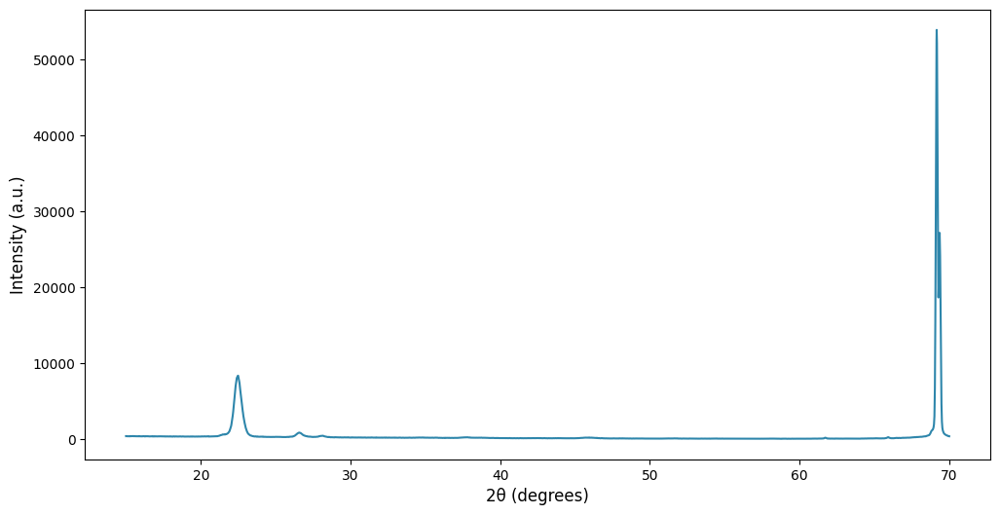

In [25]:
# Fix: Convert the data format before plotting
print("="*80)
print("🔬 FETCHING XRD DATA USING ARCHIVE QUERY ENDPOINT")
print("="*80)

test_entry_id = "-V9PT1GO34TpAPRPt3E1xjomXVWm"  # First XRD entry

# Use the archive query endpoint with specific entry ID
xrd_archive_query = {
    "owner": "visible",
    "query": {
        "entry_id": test_entry_id
    },
    "pagination": {"page_size": 1},
    "required": {"data": "*"}  # Get all data
}

print(f"\n📊 Fetching entry: {test_entry_id}")
print("-"*80)

response = requests.post(
    f"{URL}/entries/archive/query",
    headers=headers,
    json=xrd_archive_query,
    timeout=120
)

if response.status_code == 200:
    data = response.json()
    entries = data.get('data', [])
    
    if entries:
        entry = entries[0]
        archive = entry.get('archive', {})
        data_section = archive.get('data', {})
        
        print(f"✅ Data retrieved successfully!")
        print(f"\n📋 Top-level data keys: {list(data_section.keys())}")
        
        # Look for XRD pattern data
        print(f"\n{'='*80}")
        print("🔍 SEARCHING FOR XRD PATTERN DATA")
        print('='*80)
        
        # Deep search for two_theta and intensity
        def find_xrd_data(obj, path=""):
            """Recursively search for two_theta and intensity arrays"""
            if isinstance(obj, dict):
                # Check if this dict has both two_theta and intensity
                if 'two_theta' in obj and 'intensity' in obj:
                    return path, obj
                
                # Check for alternative naming
                if 'angle' in obj and 'intensity' in obj:
                    return path, obj
                
                if 'x' in obj and 'y' in obj:
                    return path, obj
                
                # Recursively search in sub-dicts
                for key, value in obj.items():
                    result = find_xrd_data(value, f"{path}.{key}" if path else key)
                    if result:
                        return result
            
            elif isinstance(obj, list):
                for i, item in enumerate(obj):
                    result = find_xrd_data(item, f"{path}[{i}]")
                    if result:
                        return result
            
            return None
        
        xrd_location = find_xrd_data(data_section)
        
        if xrd_location:
            path, xrd_dict = xrd_location
            print(f"✅ FOUND XRD DATA at: {path}")
            print(f"\nData keys: {list(xrd_dict.keys())}")
            
            # Extract the data
            two_theta = xrd_dict.get('two_theta') or xrd_dict.get('angle') or xrd_dict.get('x')
            intensity = xrd_dict.get('intensity') or xrd_dict.get('y')
            
            if two_theta and intensity:
                print(f"\n📊 XRD Data Found!")
                print(f"   Two-theta points: {len(two_theta)}")
                print(f"   Intensity points: {len(intensity)}")
                print(f"   Sample values:")
                print(f"      2θ: {two_theta[:5]}")
                print(f"      I:  {intensity[:5]}")
                
                # Create dictionary format for plotting
                xrd_data = {
                    'two_theta': two_theta,
                    'intensity': intensity
                }
                
                print(f"\n📈 Plotting XRD spectrum...")
                plot_xrd_spectrum(xrd_data, test_entry_id)
                
                print(f"\n✅ SUCCESS! XRD spectrum plotted!")
                print(f"💾 Files saved:")
                print(f"   • xrd_spectrum_{test_entry_id}.png")
                print(f"   • xrd_spectrum_{test_entry_id}.csv")
        else:
            print(f"❌ Could not find two_theta/intensity data")
            print(f"\n📄 Showing structure of main sections:")
            
            for section_name in ['results', 'figures', 'xrd_settings']:
                if section_name in data_section:
                    print(f"\n--- {section_name} ---")
                    section = data_section[section_name]
                    print(json.dumps(section, indent=2)[:1000])
    
    else:
        print(f"❌ No entries returned")
        
else:
    print(f"❌ Error: {response.status_code}")
    print(f"   {response.text[:500]}")

print("\n" + "="*80)


🔬 FETCHING XRD DATA USING ARCHIVE QUERY ENDPOINT

📊 Fetching entry: -V9PT1GO34TpAPRPt3E1xjomXVWm
--------------------------------------------------------------------------------
✅ Data retrieved successfully!

📋 Top-level data keys: ['m_def', 'name', 'datetime', 'lab_id', 'location', 'data_files', 'samples', 'results', 'xrd_settings', 'figures']

🔍 SEARCHING FOR XRD PATTERN DATA
✅ FOUND XRD DATA at: results[0]

Data keys: ['name', 'x_absolute', 'y_absolute', 'intensity', 'two_theta', 'q_norm', 'omega', 'phi', 'chi', 'source_peak_wavelength', 'scan_axis', 'integration_time']

📊 XRD Data Found!
   Entry name: anait 0016 Ba FL XRD
   Two-theta points: 5501
   Intensity points: 5501
   Sample values:
      2θ: [15.0, 15.01, 15.02, 15.03, 15.04]
      I:  [426.651885986328, 431.422332763672, 436.874298095703, 439.088317871094, 428.882110595703]

📈 Plotting XRD spectrum...
💾 Plot saved to: xrd_spectrum_-V9PT1GO34TpAPRPt3E1xjomXVWm.png


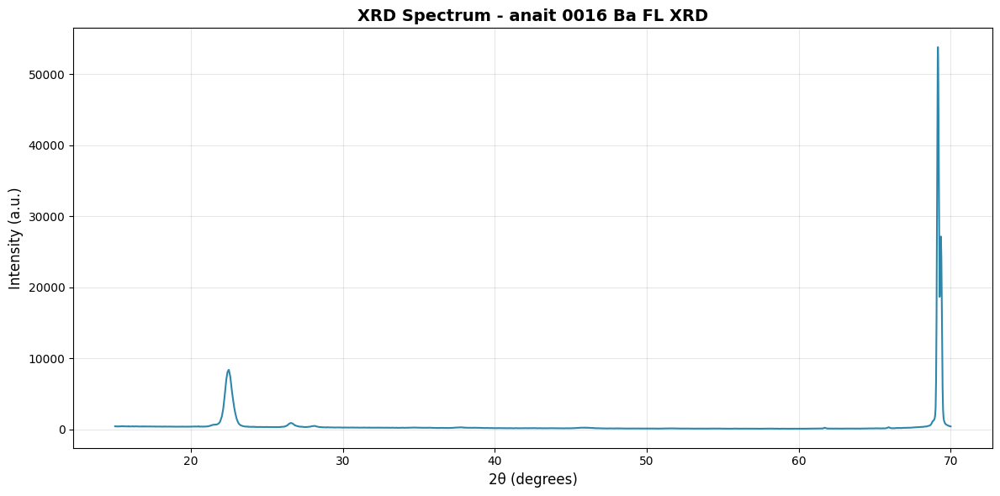


✅ SUCCESS! XRD spectrum plotted!
💾 Files saved:
   • xrd_spectrum_-V9PT1GO34TpAPRPt3E1xjomXVWm.png
   • xrd_spectrum_-V9PT1GO34TpAPRPt3E1xjomXVWm.csv



In [26]:
# Fix: Add entry_name to the data dictionary
print("="*80)
print("🔬 FETCHING XRD DATA USING ARCHIVE QUERY ENDPOINT")
print("="*80)

test_entry_id = "-V9PT1GO34TpAPRPt3E1xjomXVWm"  # First XRD entry

# Use the archive query endpoint with specific entry ID
xrd_archive_query = {
    "owner": "visible",
    "query": {
        "entry_id": test_entry_id
    },
    "pagination": {"page_size": 1},
    "required": {"data": "*"}  # Get all data
}

print(f"\n📊 Fetching entry: {test_entry_id}")
print("-"*80)

response = requests.post(
    f"{URL}/entries/archive/query",
    headers=headers,
    json=xrd_archive_query,
    timeout=120
)

if response.status_code == 200:
    data = response.json()
    entries = data.get('data', [])
    
    if entries:
        entry = entries[0]
        archive = entry.get('archive', {})
        data_section = archive.get('data', {})
        
        print(f"✅ Data retrieved successfully!")
        print(f"\n📋 Top-level data keys: {list(data_section.keys())}")
        
        # Get entry name
        entry_name = data_section.get('name', data_section.get('lab_id', 'Unknown'))
        
        # Look for XRD pattern data
        print(f"\n{'='*80}")
        print("🔍 SEARCHING FOR XRD PATTERN DATA")
        print('='*80)
        
        # Deep search for two_theta and intensity
        def find_xrd_data(obj, path=""):
            """Recursively search for two_theta and intensity arrays"""
            if isinstance(obj, dict):
                # Check if this dict has both two_theta and intensity
                if 'two_theta' in obj and 'intensity' in obj:
                    return path, obj
                
                # Check for alternative naming
                if 'angle' in obj and 'intensity' in obj:
                    return path, obj
                
                if 'x' in obj and 'y' in obj:
                    return path, obj
                
                # Recursively search in sub-dicts
                for key, value in obj.items():
                    result = find_xrd_data(value, f"{path}.{key}" if path else key)
                    if result:
                        return result
            
            elif isinstance(obj, list):
                for i, item in enumerate(obj):
                    result = find_xrd_data(item, f"{path}[{i}]")
                    if result:
                        return result
            
            return None
        
        xrd_location = find_xrd_data(data_section)
        
        if xrd_location:
            path, xrd_dict = xrd_location
            print(f"✅ FOUND XRD DATA at: {path}")
            print(f"\nData keys: {list(xrd_dict.keys())}")
            
            # Extract the data
            two_theta = xrd_dict.get('two_theta') or xrd_dict.get('angle') or xrd_dict.get('x')
            intensity = xrd_dict.get('intensity') or xrd_dict.get('y')
            
            if two_theta and intensity:
                print(f"\n📊 XRD Data Found!")
                print(f"   Entry name: {entry_name}")
                print(f"   Two-theta points: {len(two_theta)}")
                print(f"   Intensity points: {len(intensity)}")
                print(f"   Sample values:")
                print(f"      2θ: {two_theta[:5]}")
                print(f"      I:  {intensity[:5]}")
                
                # Create dictionary format for plotting (with all required keys)
                xrd_data = {
                    'two_theta': two_theta,
                    'intensity': intensity,
                    'entry_name': entry_name,
                    'entry_id': test_entry_id
                }
                
                print(f"\n📈 Plotting XRD spectrum...")
                plot_xrd_spectrum(xrd_data, test_entry_id)
                
                print(f"\n✅ SUCCESS! XRD spectrum plotted!")
                print(f"💾 Files saved:")
                print(f"   • xrd_spectrum_{test_entry_id}.png")
                print(f"   • xrd_spectrum_{test_entry_id}.csv")
        else:
            print(f"❌ Could not find two_theta/intensity data")
            print(f"\n📄 Showing structure of main sections:")
            
            for section_name in ['results', 'figures', 'xrd_settings']:
                if section_name in data_section:
                    print(f"\n--- {section_name} ---")
                    section = data_section[section_name]
                    print(json.dumps(section, indent=2)[:1000])
    
    else:
        print(f"❌ No entries returned")
        
else:
    print(f"❌ Error: {response.status_code}")
    print(f"   {response.text[:500]}")

print("\n" + "="*80)


In [27]:
# Save the XRD data to CSV
print("💾 Saving XRD data to CSV...")

# Get the XRD data (should still be in memory from previous cell)
if 'xrd_data' in locals():
    # Create a DataFrame
    df = pd.DataFrame({
        '2theta': xrd_data['two_theta'],
        'intensity': xrd_data['intensity']
    })
    
    # Save to CSV
    csv_filename = f"xrd_spectrum_{test_entry_id}.csv"
    df.to_csv(csv_filename, index=False)
    
    print(f"✅ CSV file saved: {csv_filename}")
    print(f"📊 Data shape: {df.shape[0]} rows, {df.shape[1]} columns")
    print(f"\n📄 First few rows:")
    print(df.head())
    
    # Show full path
    import os
    full_path = os.path.abspath(csv_filename)
    print(f"\n📁 Full path: {full_path}")
else:
    print("❌ xrd_data not found in memory. Please run the previous cell first.")

💾 Saving XRD data to CSV...
✅ CSV file saved: xrd_spectrum_-V9PT1GO34TpAPRPt3E1xjomXVWm.csv
📊 Data shape: 5501 rows, 2 columns

📄 First few rows:
   2theta   intensity
0   15.00  426.651886
1   15.01  431.422333
2   15.02  436.874298
3   15.03  439.088318
4   15.04  428.882111

📁 Full path: c:\Users\anait\OneDrive - Danmarks Tekniske Universitet\Documents\GitHub\codes-in-progress\Anat\API\xrd_spectrum_-V9PT1GO34TpAPRPt3E1xjomXVWm.csv


In [28]:
# ============================================================================
# STEP 1: USER INPUT - Specify upload and position
# ============================================================================

# 📝 EDIT THESE VALUES:
UPLOAD_NAME = "anait_0021_Ba_BL"  # Example: "anait_0021_Ba_BL"
POSITION = "BL"  # Example: "FL", "FR", "BL", "BR", "C", etc. (or leave empty "" for all)

print("="*80)
print("🔍 SEARCHING FOR XRD MEASUREMENTS")
print("="*80)
print(f"\n📋 Search parameters:")
print(f"   Upload name: {UPLOAD_NAME}")
print(f"   Position: {POSITION if POSITION else 'All positions'}")
print("\n⏳ Searching...")

🔍 SEARCHING FOR XRD MEASUREMENTS

📋 Search parameters:
   Upload name: anait_0021_Ba_BL
   Position: BL

⏳ Searching...


In [30]:
# ============================================================================
# STEP 2: SEARCH FOR XRD MEASUREMENTS (Shows all points within each entry)
# ============================================================================

# Search for XRD entries
xrd_query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:all": ["DTUXRDMeasurement"]},
            {"authors.name": "Anat Itzhak"}
        ]
    },
    "pagination": {"page_size": 100},
    "required": {"include": ["entry_id", "entry_name", "mainfile", "upload_id"]}
}

response = requests.post(
    f"{URL}/entries/query",
    headers=headers,
    json=xrd_query,
    timeout=60
)

if response.status_code == 200:
    data = response.json()
    all_xrd_entries = data.get('data', [])
    
    # Filter by upload name and position
    matching_entries = []
    
    for entry in all_xrd_entries:
        entry_name = entry.get('entry_name', '')
        mainfile = entry.get('mainfile', '')
        
        # Check if upload name matches
        if UPLOAD_NAME.lower() in entry_name.lower() or UPLOAD_NAME.lower() in mainfile.lower():
            # Check position if specified
            if POSITION:
                if POSITION.upper() in entry_name.upper() or POSITION.upper() in mainfile.upper():
                    matching_entries.append(entry)
            else:
                matching_entries.append(entry)
    
    print("\n" + "="*80)
    print(f"📊 FOUND {len(matching_entries)} XRD ENTRY(IES)")
    print("="*80)
    
    if matching_entries:
        # Now fetch full data to see how many measurement points each has
        print(f"\n⏳ Fetching detailed information...\n")
        
        available_xrd_points = {}
        point_counter = 0
        
        for entry_idx, entry in enumerate(matching_entries, 1):
            entry_id = entry.get('entry_id')
            entry_name = entry.get('entry_name', 'Unknown')
            
            # Fetch full archive to see measurement points
            xrd_archive_query = {
                "owner": "visible",
                "query": {"entry_id": entry_id},
                "pagination": {"page_size": 1},
                "required": {"data": "*"}
            }
            
            response = requests.post(
                f"{URL}/entries/archive/query",
                headers=headers,
                json=xrd_archive_query,
                timeout=120
            )
            
            if response.status_code == 200:
                archive_data = response.json()
                entries_data = archive_data.get('data', [])
                
                if entries_data:
                    archive = entries_data[0].get('archive', {})
                    data_section = archive.get('data', {})
                    
                    # Check 'results' section for measurement points
                    results = data_section.get('results', [])
                    
                    if isinstance(results, list) and len(results) > 0:
                        num_points = len(results)
                        
                        print(f"📁 Entry [{entry_idx}]: {entry_name}")
                        print(f"   Entry ID: {entry_id}")
                        print(f"   📊 Contains {num_points} measurement point(s):")
                        print()
                        
                        # List each measurement point
                        for point_idx, result in enumerate(results, 1):
                            point_counter += 1
                            
                            # Try to get a name or identifier for this point
                            point_name = result.get('name', f'Point {point_idx}')
                            
                            # Store this point
                            available_xrd_points[point_counter] = {
                                'entry_id': entry_id,
                                'entry_name': entry_name,
                                'point_index': point_idx - 1,  # 0-based index
                                'point_name': point_name,
                                'result_data': result
                            }
                            
                            print(f"      [{point_counter}] {point_name}")
                        
                        print()
        
        print("="*80)
        print(f"✅ TOTAL: {point_counter} XRD measurement point(s) available")
        print("="*80)
        print("\n💡 NEXT STEP: In the next cell, select which point(s) to plot")
        print("   Example: SELECTED_POINTS = [1]  # Plot first point")
        print("   Example: SELECTED_POINTS = [1, 5, 10]  # Plot specific points")
        print("   Example: SELECTED_POINTS = list(range(1, 26))  # Plot all 25 points")
        print("="*80)
        
    else:
        print(f"\n❌ No XRD measurements found matching:")
        print(f"   Upload: {UPLOAD_NAME}")
        print(f"   Position: {POSITION if POSITION else 'Any'}")
        
else:
    print(f"❌ Error querying XRD entries: {response.status_code}")


📊 FOUND 1 XRD ENTRY(IES)

⏳ Fetching detailed information...

📁 Entry [1]: anait 0021 Ba BL XRD
   Entry ID: 1FWV7IADrj0BzjMtqrVjPkCmBLNb
   📊 Contains 25 measurement point(s):

      [1] Stage x = -38.0 mm, y = 38.0 mm
      [2] Stage x = -29.0 mm, y = 38.0 mm
      [3] Stage x = -20.0 mm, y = 38.0 mm
      [4] Stage x = -11.0 mm, y = 38.0 mm
      [5] Stage x = -2.0 mm, y = 38.0 mm
      [6] Stage x = -38.0 mm, y = 2.0 mm
      [7] Stage x = -29.0 mm, y = 2.0 mm
      [8] Stage x = -20.0 mm, y = 2.0 mm
      [9] Stage x = -11.0 mm, y = 2.0 mm
      [10] Stage x = -2.0 mm, y = 2.0 mm
      [11] Stage x = -38.0 mm, y = 11.0 mm
      [12] Stage x = -29.0 mm, y = 11.0 mm
      [13] Stage x = -20.0 mm, y = 11.0 mm
      [14] Stage x = -11.0 mm, y = 11.0 mm
      [15] Stage x = -2.0 mm, y = 11.0 mm
      [16] Stage x = -38.0 mm, y = 20.0 mm
      [17] Stage x = -29.0 mm, y = 20.0 mm
      [18] Stage x = -20.0 mm, y = 20.0 mm
      [19] Stage x = -11.0 mm, y = 20.0 mm
      [20] Stage x = 

In [31]:
# ============================================================================
# STEP 3: USER SELECTION - Choose which measurement point(s) to plot
# ============================================================================

# 📝 EDIT THIS VALUE - Select the measurement point(s) to plot:
SELECTED_POINTS = [1, 2, 3]  # Use the numbers from the list above

print("="*80)
print("📊 SELECTED XRD MEASUREMENT POINTS")
print("="*80)

if 'available_xrd_points' not in locals():
    print("❌ Error: Please run the previous cell first to search for XRD measurements")
else:
    selected_points = []
    
    for idx in SELECTED_POINTS:
        if idx in available_xrd_points:
            point_info = available_xrd_points[idx]
            selected_points.append(point_info)
            print(f"\n✅ [{idx}] {point_info['entry_name']} - {point_info['point_name']}")
        else:
            print(f"\n⚠️  [{idx}] Invalid selection (not in available list)")
    
    if selected_points:
        print(f"\n{'='*80}")
        print(f"📈 Ready to plot {len(selected_points)} XRD measurement point(s)")
        print(f"{'='*80}")
        print(f"\n💡 Run the next cell to fetch data and plot!")
    else:
        print(f"\n❌ No valid selections. Please check SELECTED_POINTS values.")

📊 SELECTED XRD MEASUREMENT POINTS

✅ [1] anait 0021 Ba BL XRD - Stage x = -38.0 mm, y = 38.0 mm

✅ [2] anait 0021 Ba BL XRD - Stage x = -29.0 mm, y = 38.0 mm

✅ [3] anait 0021 Ba BL XRD - Stage x = -20.0 mm, y = 38.0 mm

📈 Ready to plot 3 XRD measurement point(s)

💡 Run the next cell to fetch data and plot!


📊 PROCESSING 3 XRD MEASUREMENT POINT(S)

[1/3] Processing: anait 0021 Ba BL XRD - Stage x = -38.0 mm, y = 38.0 mm
--------------------------------------------------------------------------------
   ✅ Data found: 5501 points
   📈 Plotting...
💾 Plot saved to: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png


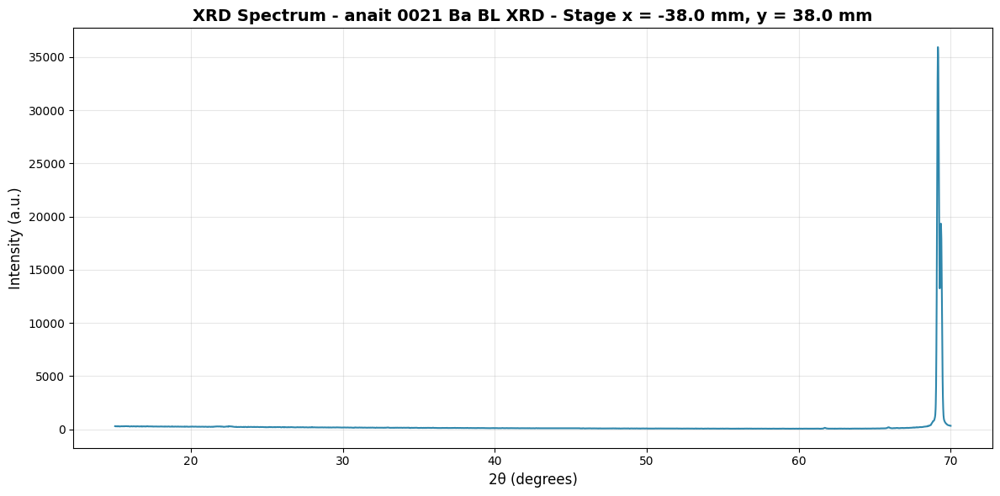

   💾 Saved: xrd_anait_0021_Ba_BL_XRD_Stage_x_=_-38.0_mm,_y_=_38.0_mm.csv
   💾 Saved: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png

[2/3] Processing: anait 0021 Ba BL XRD - Stage x = -29.0 mm, y = 38.0 mm
--------------------------------------------------------------------------------
   ✅ Data found: 5501 points
   📈 Plotting...
💾 Plot saved to: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png


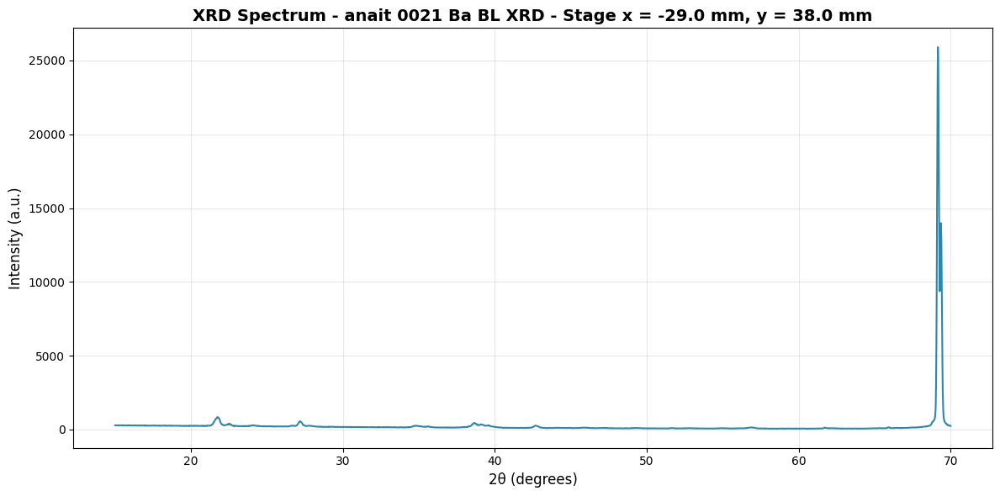

   💾 Saved: xrd_anait_0021_Ba_BL_XRD_Stage_x_=_-29.0_mm,_y_=_38.0_mm.csv
   💾 Saved: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png

[3/3] Processing: anait 0021 Ba BL XRD - Stage x = -20.0 mm, y = 38.0 mm
--------------------------------------------------------------------------------
   ✅ Data found: 5501 points
   📈 Plotting...
💾 Plot saved to: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png


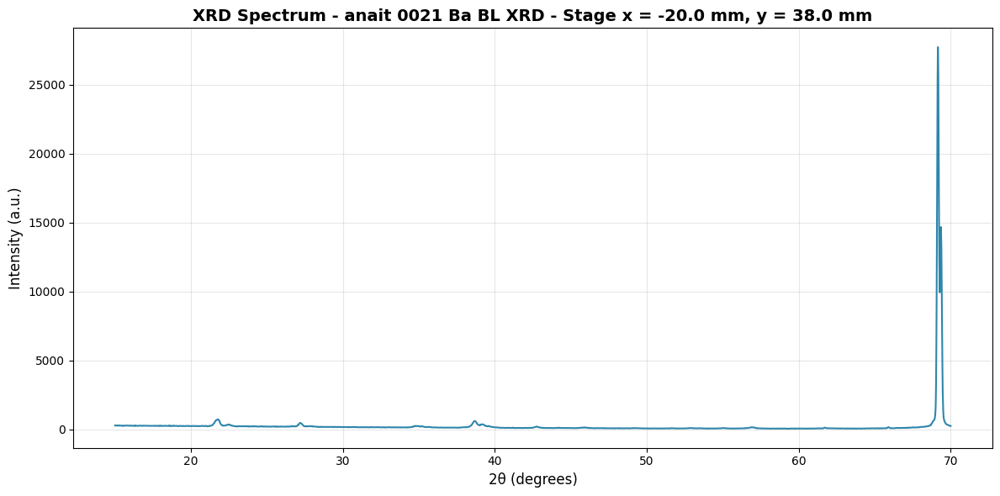

   💾 Saved: xrd_anait_0021_Ba_BL_XRD_Stage_x_=_-20.0_mm,_y_=_38.0_mm.csv
   💾 Saved: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png

✅ COMPLETED! Successfully plotted 3/3 point(s)

📁 Files saved in current directory:
   c:\Users\anait\OneDrive - Danmarks Tekniske Universitet\Documents\GitHub\codes-in-progress\Anat\API


In [32]:
# ============================================================================
# STEP 4: FETCH DATA, PLOT, AND SAVE
# ============================================================================

if 'selected_points' not in locals() or not selected_points:
    print("❌ Error: Please run the previous cells first and select measurement points")
else:
    print("="*80)
    print(f"📊 PROCESSING {len(selected_points)} XRD MEASUREMENT POINT(S)")
    print("="*80)
    
    successfully_plotted = 0
    
    for i, point_info in enumerate(selected_points, 1):
        entry_name = point_info['entry_name']
        point_name = point_info['point_name']
        result_data = point_info['result_data']
        
        print(f"\n[{i}/{len(selected_points)}] Processing: {entry_name} - {point_name}")
        print("-"*80)
        
        # Search for XRD pattern data in this result
        def find_xrd_data(obj, path=""):
            if isinstance(obj, dict):
                if 'two_theta' in obj and 'intensity' in obj:
                    return path, obj
                if 'angle' in obj and 'intensity' in obj:
                    return path, obj
                if 'x' in obj and 'y' in obj:
                    return path, obj
                for key, value in obj.items():
                    result = find_xrd_data(value, f"{path}.{key}" if path else key)
                    if result:
                        return result
            elif isinstance(obj, list):
                for idx, item in enumerate(obj):
                    result = find_xrd_data(item, f"{path}[{idx}]")
                    if result:
                        return result
            return None
        
        xrd_location = find_xrd_data(result_data)
        
        if xrd_location:
            path, xrd_dict = xrd_location
            
            # Extract data
            two_theta = xrd_dict.get('two_theta') or xrd_dict.get('angle') or xrd_dict.get('x')
            intensity = xrd_dict.get('intensity') or xrd_dict.get('y')
            
            if two_theta and intensity:
                print(f"   ✅ Data found: {len(two_theta)} points")
                
                # Create data dictionary
                xrd_data = {
                    'two_theta': two_theta,
                    'intensity': intensity,
                    'entry_name': f"{entry_name} - {point_name}",
                    'entry_id': point_info['entry_id']
                }
                
                # Plot
                print(f"   📈 Plotting...")
                plot_xrd_spectrum(xrd_data, point_info['entry_id'])
                
                # Save CSV with unique name
                df = pd.DataFrame({
                    '2theta': two_theta,
                    'intensity': intensity
                })
                safe_name = f"{entry_name}_{point_name}".replace(' ', '_').replace('/', '_')
                csv_filename = f"xrd_{safe_name}.csv"
                df.to_csv(csv_filename, index=False)
                
                print(f"   💾 Saved: {csv_filename}")
                print(f"   💾 Saved: xrd_spectrum_{point_info['entry_id']}.png")
                
                successfully_plotted += 1
            else:
                print(f"   ❌ Could not extract two_theta/intensity arrays")
        else:
            print(f"   ❌ No XRD pattern data found")
    
    print("\n" + "="*80)
    print(f"✅ COMPLETED! Successfully plotted {successfully_plotted}/{len(selected_points)} point(s)")
    print("="*80)
    
    if successfully_plotted > 0:
        print(f"\n📁 Files saved in current directory:")
        import os
        print(f"   {os.getcwd()}")